In [18]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Tue Jun  7 12:02:15 2022

@author: sunms498
"""

'\nCreated on Tue Jun  7 12:02:15 2022\n\n@author: sunms498\n'

## Load libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame
import matplotlib.colors as colors
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from matplotlib.colors import LogNorm
import cmcrameri.cm as cmc
import cmocean as cmo
ds = 2.6 #bulk density of marine soil
import sys
module_path = Path().resolve().parents[1] / "src" / "postprocessing"
import matplotlib.pyplot as plt
# Append the directory to sys.path
sys.path.append(str(module_path))


from visualizePredictionMap import *

In [2]:
"""
constraint = 0.1
layer_widths_all = [[512]*3, [512]*4, [512]*5, [512]*6, [512]*7, [512]*8, [128]*3, [128]*4, [128]*5, [128]*6, [128]*7, [128]*8, [64]*3, [64]*4, [64]*5, [64]*6, [64]*7, [64]*8]
num_shared_layers_all = [1, 2, 3, 4, 5, 6, 7, 8]
count_mtl = 0
for layer_width in layer_widths_all:
    for num_shared_layers in num_shared_layers_all:
        count_mtl = count_mtl + 1
        layer_widths = layer_width
        num_shared_layers = num_shared_layers
        if num_shared_layers > len(layer_widths):
            continue
        print("*"*10)
        print(count_mtl)
        print(layer_widths)
        print(num_shared_layers)
"""

'\nconstraint = 0.1\nlayer_widths_all = [[512]*3, [512]*4, [512]*5, [512]*6, [512]*7, [512]*8, [128]*3, [128]*4, [128]*5, [128]*6, [128]*7, [128]*8, [64]*3, [64]*4, [64]*5, [64]*6, [64]*7, [64]*8]\nnum_shared_layers_all = [1, 2, 3, 4, 5, 6, 7, 8]\ncount_mtl = 0\nfor layer_width in layer_widths_all:\n    for num_shared_layers in num_shared_layers_all:\n        count_mtl = count_mtl + 1\n        layer_widths = layer_width\n        num_shared_layers = num_shared_layers\n        if num_shared_layers > len(layer_widths):\n            continue\n        print("*"*10)\n        print(count_mtl)\n        print(layer_widths)\n        print(num_shared_layers)\n'

## Load data

In [38]:
#Load prediction maps and uncertainty maps from the monte carlo dropout for both continental shelves and deep ocean models
#"""
layer_widths =[512, 256, 128, 64, 32, 16, 8, 4, 2]
#/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_entire_supervised_[512, 256, 128, 64].npy
filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_entire_nn_n2.npy"
#prediction_map_MAR_CS_MTL_n_3.npy"##Path().resolve().parents[2] / "toc-infoshap" / "data" / "output" / "predictionmaps_TOC" / "prediction_map_TOC_CS_top10infoSHAP.npy"

prediction_map_CS = np.load(filename)
#layer_widths =[512]*10
prediction_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_entire_nn_n2.npy")#Path().resolve().parents[2] / "toc-infoshap" / "data" / "output" / "predictionmaps_TOC" / "prediction_map_TOC_DO_top10infoSHAP.npy")


#prediction_map_CS = np.rot90(np.rot90(np.fliplr(prediction_map_CS)))
#prediction_map_DO = np.rot90(np.rot90(np.fliplr(prediction_map_DO)))

In [39]:
# Overlap both the deep ocean and the continental shelves
# pm: prediction map, um_uncertaintymap
dataset_mask = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))
#prediction_map_DO = np.rot90(np.rot90(np.fliplr(prediction_map_DO)))
#prediction_map_CS = np.rot90(np.rot90(np.fliplr(prediction_map_CS)))
# Create a copy of pm_CS
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]



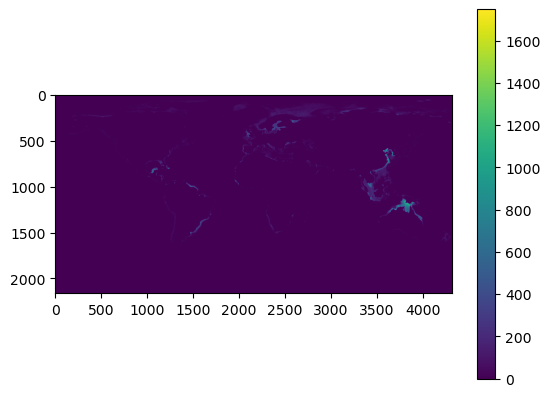

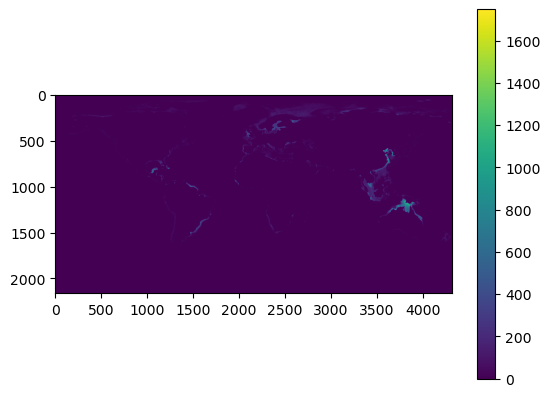

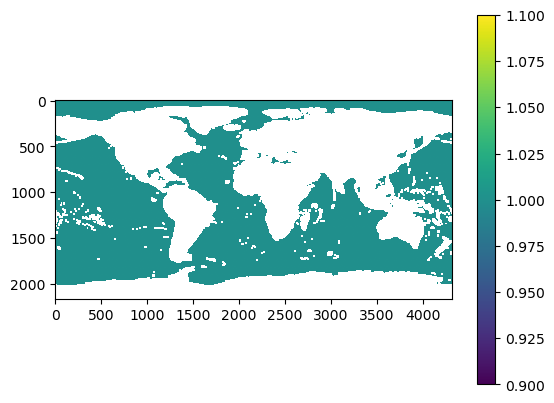

In [40]:
plt.imshow(prediction_map_CS)
plt.colorbar()
plt.show()

plt.imshow(prediction_map_DO)
plt.colorbar()
plt.show()

plt.imshow(dataset_mask)
plt.colorbar()
plt.show()

In [41]:

#restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
#restrepo_features_path = Path("/gxfs_work/cau/sunms498/work_old/Data/Features_PhrampusLee_noNaN_highres_rot/")
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    #print(filenames)
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)


file_idx = -1
corrupted_files = 0
rootgrp = xr.open_dataset(Path(restrepo_features_path / restrepo_files[0]), format = 'NETCDF4')

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1

    if file == "SF_POROSITY_FRC.5m_with_coords_flip.nc":
        porosity_fileidx = file_idx
        print(porosity_fileidx)
        
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        except:
            restrepo_X_mean = np.append(restrepo_X_mean,np.nan)
            restrepo_X_std = np.append(restrepo_X_std,np.nan)
            corrupted_files=+1
            continue
        dataset_numpy_porosity = rootgrp.variables['data']


253


In [42]:

# make area of the cells file, based on the latitude


restrepo_features_path = Path().resolve().parents[1] / "data" / "raw" / "features" / "FeaturesPhrampusLee_TOCSedRate_updated" / "GL_LATITUDE_DD.5m.nc"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']


file_idx = -1
corrupted_files = 0

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi) # in km2

In [43]:
# overlay land boundaries on the prediction and uncertainty maps

land_file = Path().resolve().parents[1] / "data" / "raw" / "island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1

# Set land to np.nan so it is masked in the plot
pm_overlapped_masked = pm_overlapped.copy()
pm_overlapped_masked[land_map.astype(bool)] = np.nan

# For MAR, set only land to np.nan, but for MAR <= 0, set to a small value (e.g., vmin/10) so they are visible on the log scale
MAR = pm_overlapped_masked


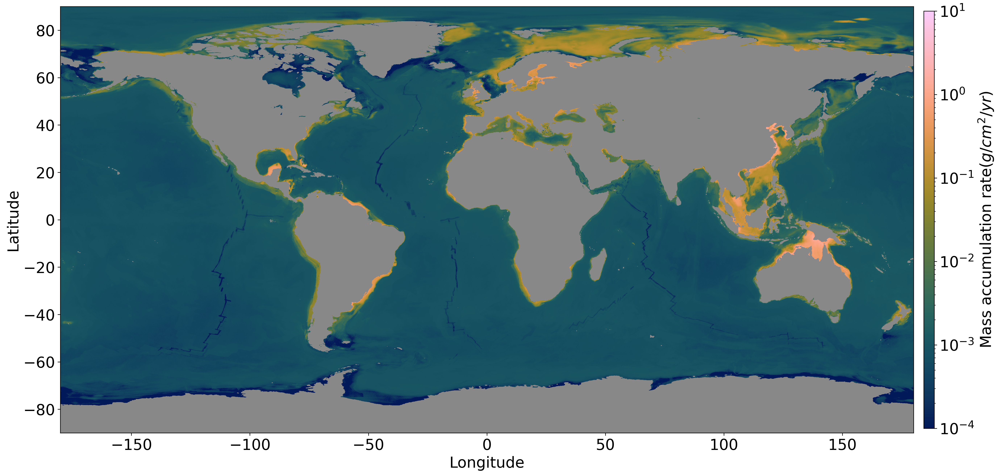

In [44]:

MAR_plot = MAR
small_value = 1e-3  # smaller than vmin=1e-2, but not too small for log scale
MAR_plot = np.where(np.isnan(MAR), np.nan, np.where(MAR <= 0, small_value, MAR))

# Set the color for NaN values to a darker color (e.g., dark gray)

cmap = cmc.batlow.copy()
cmap.set_bad(color='#888888')  # a little darker gray for NaNs

VisualiseMap((MAR_plot)/1e3, cmap=cmap, use_log_norm=True, vmin=1e-4, vmax=1e1, 
             cbar_label="Mass accumulation rate($g/cm^2/yr$)", 
             save_path="../../data/figs/mar/mar_noconstraint.png")

In [45]:
"""f
rom matplotlib.colors import LogNorm

#MAR_plot = MAR

#MAR_plot = MAR_plot/1e3

#MAR_plot = np.rot90(np.rot90(np.fliplr(MAR_plot)))
small_value = 1e-3  # smaller than vmin=1e-2, but not too small for log scale
MAR_plot = np.where(np.isnan(MAR), np.nan, np.where(MAR <= 0, small_value, MAR/1e3))
elevation_file = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"

# Set the color for NaN values to a darker color (e.g., dark gray)
cmap = cmc.lajolla.copy()
cmap.set_bad(color='#888888')  # a little darker gray for NaNs

# ---- Find MAR at key sites ----
australia_sites = [
    # Western Tasman Sea
    {"name": "S2",  "lat": -41-25/60, "lon": 148+47/60, "depth": 1015, "MAR_lit": 57},
    {"name": "S3",  "lat": -39-17/60, "lon": 148+55/60, "depth": 1249, "MAR_lit": 74},
    {"name": "S4",  "lat": -37-41/60, "lon": 150+18/60, "depth": 732,  "MAR_lit": 125},
    {"name": "S5",  "lat": -35-27/60, "lon": 150+51/60, "depth": 765,  "MAR_lit": 222},
    {"name": "S8",  "lat": -28-5/60,  "lon": 154+1/60,  "depth": 586,  "MAR_lit": 53},
    {"name": "S10", "lat": -27-39/60, "lon": 154+2/60,  "depth": 954,  "MAR_lit": 41},
    # Southern Australian margin
    {"name": "S11", "lat": -32-17/60, "lon": 114+33/60, "depth": 1034, "MAR_lit": 47},
    {"name": "S15", "lat": -34-46/60, "lon": 119+39/60, "depth": 1080, "MAR_lit": 28},
    {"name": "S17", "lat": -34-41/60, "lon": 122+41/60, "depth": 726,  "MAR_lit": 52},
    {"name": "S18", "lat": -34-15/60, "lon": 125+17/60, "depth": 1297, "MAR_lit": 41},
    {"name": "MUC03", "lat": -36-43/60, "lon": 136+48/60, "depth": 949, "MAR_lit": 100},
    {"name": "S19", "lat": -37-53/60, "lon": 139+36/60, "depth": 1117, "MAR_lit": 37},
    {"name": "S20", "lat": -39-11/60, "lon": 142+29/60, "depth": 1160, "MAR_lit": 36},
    {"name": "S21", "lat": -42-46/60, "lon": 144+48/60, "depth": 1277, "MAR_lit": 32},
]

def find_nearest_idx(array, value):
    array = np.asarray(array)
    return (np.abs(array - value)).argmin()
MAR_plot = np.rot90(np.rot90(np.fliplr(MAR_plot)))
site_results = []
for site in australia_sites:
    lat_idx = find_nearest_idx(latitudes, site["lat"])
    lon_idx = find_nearest_idx(longitudes, site["lon"])
    mar_model = MAR_plot[lat_idx, lon_idx]  # MAR in g/cm2/yr
    mar_model_mgcm2yr = mar_model *1e3  if not np.isnan(mar_model) else np.nan
    site['lat_idx'] = lat_idx
    site['lon_idx'] = lon_idx
    site['MAR_model'] = mar_model
    site['MAR_model_mgcm2yr'] = mar_model_mgcm2yr
    site_results.append(site)

print("Site |   Lat  |   Lon  | MAR_lit (mg/cm2/yr) | MAR_model (mg/cm2/yr)")
for s in site_results:
    mar_val = f"{s['MAR_model_mgcm2yr']:.3f}" if np.isfinite(s['MAR_model_mgcm2yr']) else "NaN"
    print(f"{s['name']:6s} | {s['lat']:+8.3f} | {s['lon']:+8.3f} | {s['MAR_lit']:.3f}              | {mar_val}")

# --- Plot MAR map centered around Australia in mg/cm^2/yr using VisualiseMap ---
# Australia: approx 110E - 155E,  -48S - -10S
australia_lat_min, australia_lat_max = -48, -10
australia_lon_min, australia_lon_max = 110, 155

# Note: VisualiseMap expects the data to be in g/m2/yr (current) and displays it as needed.
# We'll multiply by 0.1 inside the call to VisualiseMap to get mg/cm^2/yr, if you want to plot in those units.
MAR_plot = np.rot90(np.rot90(np.fliplr(MAR_plot)))
def VisualiseMap_with_sites_and_zoom(data, cmap, vmin, vmax, cbar_label, site_list, lat_range, lon_range):
"""
    #Wrapper for VisualiseMap to allow overlaying site locations on a zoomed region using lat_range/lon_range.
"""
    # Call VisualiseMap to plot the map region (show=False to prevent double plotting)
    VisualiseMap(data * 1000, cmap=cmap, use_log_norm=True,
                 vmin=vmin, vmax=vmax, cbar_label=cbar_label,
                 lat_range=lat_range, lon_range=lon_range, show=False)  # Added show=False
    # Overlay the site points on the current figure
    for s in site_list:
        if (lat_range[0] <= s['lat'] <= lat_range[1]) and (lon_range[0] <= s['lon'] <= lon_range[1]):
            plt.plot(s['lon'], s['lat'], 'wo', markeredgecolor='k', markersize=8, label=s['name'])
            plt.text(s['lon']+0.3, s['lat'], s['name'], color='k', fontsize=8, va='center', ha='left', weight='bold')
    plt.tight_layout()
    plt.show()  # Show once with both map and sites

VisualiseMap_with_sites_and_zoom(
    MAR_plot,
    cmap=cmap,
    vmin=1e-1, vmax=1e5,
    cbar_label="Mass accumulation rate (mg/cm²/yr)",
    site_list=site_results,
    lat_range=(australia_lat_min, australia_lat_max),
    lon_range=(australia_lon_min, australia_lon_max)
)
"""

'\n    # Call VisualiseMap to plot the map region (show=False to prevent double plotting)\n    VisualiseMap(data * 1000, cmap=cmap, use_log_norm=True,\n                 vmin=vmin, vmax=vmax, cbar_label=cbar_label,\n                 lat_range=lat_range, lon_range=lon_range, show=False)  # Added show=False\n    # Overlay the site points on the current figure\n    for s in site_list:\n        if (lat_range[0] <= s[\'lat\'] <= lat_range[1]) and (lon_range[0] <= s[\'lon\'] <= lon_range[1]):\n            plt.plot(s[\'lon\'], s[\'lat\'], \'wo\', markeredgecolor=\'k\', markersize=8, label=s[\'name\'])\n            plt.text(s[\'lon\']+0.3, s[\'lat\'], s[\'name\'], color=\'k\', fontsize=8, va=\'center\', ha=\'left\', weight=\'bold\')\n    plt.tight_layout()\n    plt.show()  # Show once with both map and sites\n\nVisualiseMap_with_sites_and_zoom(\n    MAR_plot,\n    cmap=cmap,\n    vmin=1e-1, vmax=1e5,\n    cbar_label="Mass accumulation rate (mg/cm²/yr)",\n    site_list=site_results,\n    lat_ran

In [46]:
"""
import xarray as xr
elevation_file = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"
def get_elevation_at_site(lat, lon):
    lat_idx = find_nearest_idx(elev_lats, lat)
    lon_idx = find_nearest_idx(elev_lons, lon)
    return elev.values[lat_idx, lon_idx]

# --- Load elevation grid ---
ds_elev = xr.open_dataset(elevation_file)

# Inspect variable names if needed
print(ds_elev)

elev = ds_elev[list(ds_elev.data_vars)[0]]  # first data variable
elev_lats = ds_elev['lat'].values
elev_lons = ds_elev['lon'].values
for site in australia_sites:
    lat_idx = find_nearest_idx(latitudes, site["lat"])
    lon_idx = find_nearest_idx(longitudes, site["lon"])

    mar_model = MAR_plot[lat_idx, lon_idx]  # g/cm2/yr
    mar_model_mgcm2yr = mar_model * 1e3 if not np.isnan(mar_model) else np.nan

    elev_model = get_elevation_at_site(site["lat"], site["lon"])

    site['lat_idx'] = lat_idx
    site['lon_idx'] = lon_idx
    site['MAR_model'] = mar_model
    site['MAR_model_mgcm2yr'] = mar_model_mgcm2yr
    site['Elevation_model_mASL'] = elev_model

    site_results.append(site)
print("Site |   Lat  |   Lon  | MAR_lit | MAR_model | Elevation (m ASL)")
for s in site_results:
    mar_val = f"{s['MAR_model_mgcm2yr']:.2f}" if np.isfinite(s['MAR_model_mgcm2yr']) else "NaN"
    elev_val = f"{s['Elevation_model_mASL']:.0f}" if np.isfinite(s['Elevation_model_mASL']) else "NaN"

    print(
        f"{s['name']:6s} | "
        f"{s['lat']:+8.3f} | "
        f"{s['lon']:+8.3f} | "
        f"{s['MAR_lit']:7.1f} | "
        f"{mar_val:9s} | "
        f"{elev_val:>8s}"
    )
"""

'\nimport xarray as xr\nelevation_file = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"\ndef get_elevation_at_site(lat, lon):\n    lat_idx = find_nearest_idx(elev_lats, lat)\n    lon_idx = find_nearest_idx(elev_lons, lon)\n    return elev.values[lat_idx, lon_idx]\n\n# --- Load elevation grid ---\nds_elev = xr.open_dataset(elevation_file)\n\n# Inspect variable names if needed\nprint(ds_elev)\n\nelev = ds_elev[list(ds_elev.data_vars)[0]]  # first data variable\nelev_lats = ds_elev[\'lat\'].values\nelev_lons = ds_elev[\'lon\'].values\nfor site in australia_sites:\n    lat_idx = find_nearest_idx(latitudes, site["lat"])\n    lon_idx = find_nearest_idx(longitudes, site["lon"])\n\n    mar_model = MAR_plot[lat_idx, lon_idx]  # g/cm2/yr\n    mar_model_mgcm2yr = mar_model * 1e3 if not np.isnan(mar_model) else np.nan\n\n    elev_model = get_elevation_at_site(site["lat"], site["lon"])\n\n    site[\'lat_idx\']

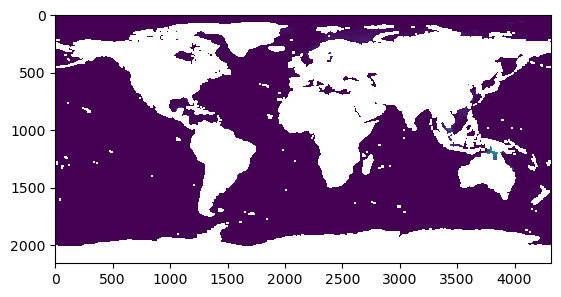

In [47]:
plt.imshow(MAR_plot)

In [48]:
#feature_image_path ="/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/"
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
#restrepo_features_path_flipped = Path("/media/sunms498/EXTERNAL_USB/Features_Phrampus_flipped")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']

# restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
# restrepo_features[:] = np.nan
# restrepo_X_mean = np.empty(0)
# restrepo_X_std = np.empty(0)

file_idx = -1
corrupted_files = 0


 
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')


    
#     latitudes = rootgrp.variables['lats'] # in theory all the same
#     longitudes = rootgrp.variables['lons']

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)


In [49]:
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
global_sed_budget_Pg = (np.nansum(np.multiply(MAR_plot,area_np*1e10))/1e3)/1e15
print(f"Global sediment budget: {(global_sed_budget_Pg):.2f} Pg/yr")


Global sediment budget: 31.43 Pg/yr


In [17]:
# MAR vs depth

restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    #print(filenames)
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

file_idx = -1
corrupted_files = 0
Depth = None  # Initialize Depth variable

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1

    if file == "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd":
        Depth_fileidx = file_idx
        print(Depth_fileidx)
        
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        except Exception as e:
            # If you have arrays to append to, uncomment below
            # restrepo_X_mean = np.append(restrepo_X_mean, np.nan)
            # restrepo_X_std = np.append(restrepo_X_std, np.nan)
            corrupted_files += 1
            continue
        dataset_numpy_Depth = rootgrp.variables['data']
        Depth = np.array(dataset_numpy_Depth)
        break  # Stop after finding and loading Depth
Depth = np.rot90(np.rot90(np.fliplr(Depth)))
Depth[land_map] = np.nan

71


In [18]:
#plt.imshow(Depth)

#VisualiseMap(Depth, cmap=cmc.tokyo, use_log_norm=False, #vmin=0, vmax=3, 
             #cbar_label="Elevation", save_path="../../data/figs/elevation.png")

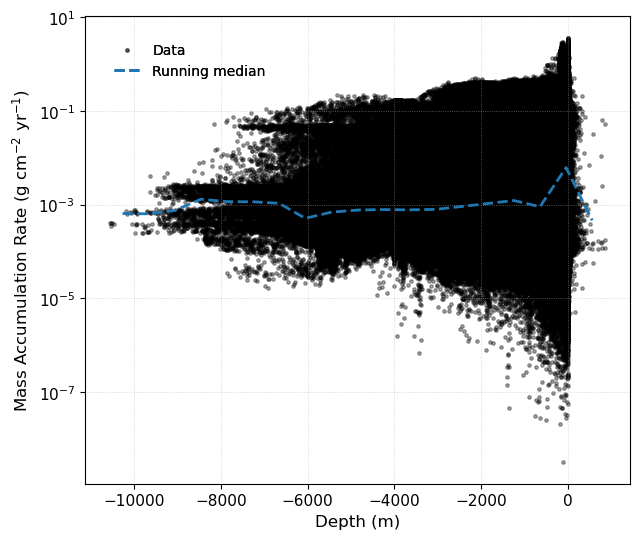

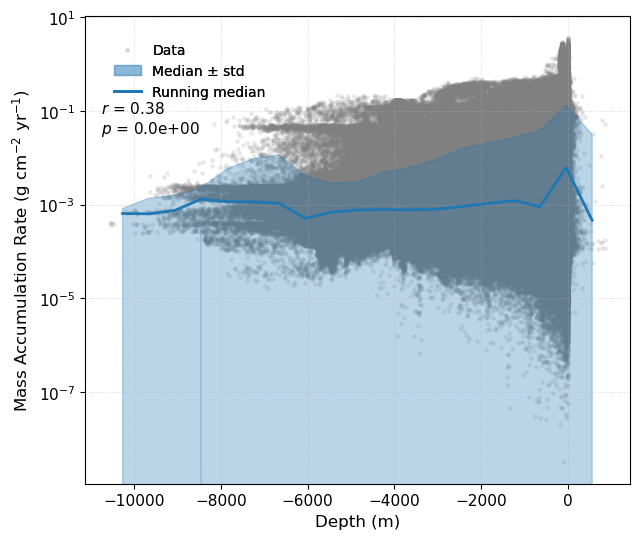

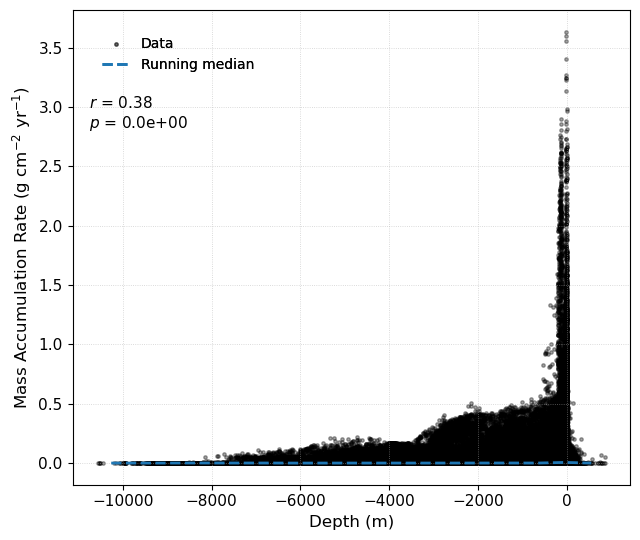

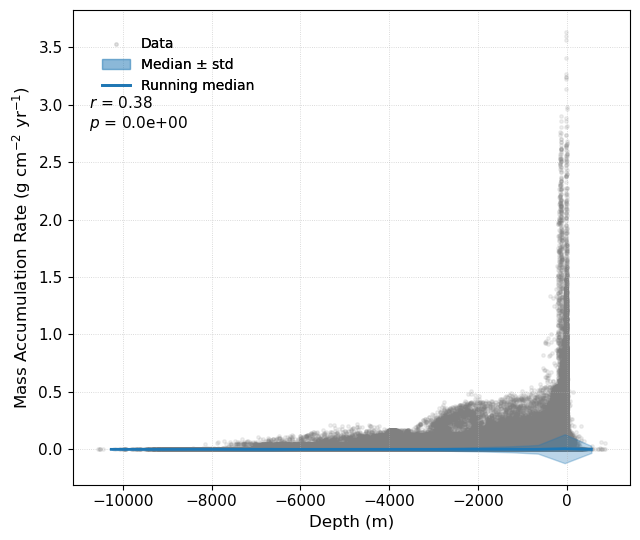

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# -----------------------
# Data preparation
# -----------------------
MAR_cm2 = MAR / 1e3

mar_flat = MAR_cm2.flatten()
depth_flat = Depth.flatten()

mask = np.isfinite(mar_flat) & np.isfinite(depth_flat) & (mar_flat > 0)
mar = mar_flat[mask]
depth = depth_flat[mask]

# -----------------------
# Statistics
# -----------------------
r, p = pearsonr(np.log10(mar), depth)

# -----------------------
# Running median and std MAR at binned depths
# -----------------------
# Choose depth bins (make bins bigger by decreasing number of bins)
# Old: 40 bins, now try 20 (twice as wide)
depth_bins = np.linspace(np.nanmin(depth), np.nanmax(depth), 20)
depth_bin_centers = 0.5 * (depth_bins[:-1] + depth_bins[1:])
mar_median = []
mar_std = []
mar_count = []

for d0, d1 in zip(depth_bins[:-1], depth_bins[1:]):
    m = (depth >= d0) & (depth < d1)
    in_bin = mar[m]
    n = len(in_bin)
    mar_count.append(n)
    if n > 0:
        mar_median.append(np.median(in_bin))
        if n == 1:
            # For single point: std is the data value itself (per instruction)
            mar_std.append(in_bin[0])
        elif n == 2:
            # For two points: std is the min point in the bin (per instruction)
            mar_std.append(np.min(in_bin))
        else:
            mar_std.append(np.std(in_bin))
    else:
        mar_median.append(np.nan)
        mar_std.append(np.nan)

mar_median = np.array(mar_median)
mar_std = np.array(mar_std)
mar_count = np.array(mar_count)
valid = np.isfinite(mar_median) & np.isfinite(mar_std)

# -----------------------
# Plot 1: As before (log-scale y axis)
# -----------------------
fig, ax = plt.subplots(figsize=(6.5, 5.5))

scatter = ax.scatter(
    depth,
    mar,
    s=6,
    color="black",
    alpha=0.35,
    rasterized=True,
    label="Data"
)

median_line, = ax.plot(
    depth_bin_centers[valid],
    mar_median[valid],
    color="tab:blue",
    lw=2,
    linestyle="--",
    label="Running median"
)

ax.set_yscale("log")
ax.set_xlabel("Depth (m)", fontsize=12)
ax.set_ylabel("Mass Accumulation Rate (g cm$^{-2}$ yr$^{-1}$)", fontsize=12)

ax.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.6)
ax.tick_params(labelsize=11)

handles, labels = ax.get_legend_handles_labels()
legend = ax.legend(handles, labels, frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.03, 0.97))
ax.add_artist(legend)

# Annotate for bins with low counts, and visually check count per bin
for x, y, n in zip(depth_bin_centers, mar_median, mar_count):
    if n <= 2 and np.isfinite(y):
        ax.text(x, y, f"n={n}", color="red", fontsize=6, ha="center", va="bottom")
"""
ax.text(
    0.03, 0.82,
    f"$r$ = {r:.2f}\n$p$ = {p:.1e}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11
)
"""
plt.tight_layout()
plt.show()

# -----------------------
# Plot 2: Median trend with standard deviation envelope (log-scale y axis)
# -----------------------
fig2, ax2 = plt.subplots(figsize=(6.5, 5.5))

# Scatter (light background for context)
ax2.scatter(
    depth,
    mar,
    s=6,
    color="grey",
    alpha=0.12,
    rasterized=True,
    label="Data"
)

# Shaded region for ±1 std around the median
# But show a warning if bin count is low
envelope_lo = mar_median[valid] - mar_std[valid]
envelope_hi = mar_median[valid] + mar_std[valid]
bin_counts_valid = mar_count[valid]

ax2.fill_between(
    depth_bin_centers[valid],
    envelope_lo,
    envelope_hi,
    color="tab:blue",
    alpha=0.3,
    label="Median ± std"
)

# Optionally: Mark bins where std is missing/small count
for x, c in zip(depth_bin_centers[valid], bin_counts_valid):
    if c <= 2:
        ax2.axvline(x, color="red", lw=0.4, ls="--", alpha=0.5)

# Median trend line
ax2.plot(
    depth_bin_centers[valid],
    mar_median[valid],
    color="tab:blue",
    lw=2,
    linestyle="-",
    label="Running median"
)

ax2.set_yscale("log")
ax2.set_xlabel("Depth (m)", fontsize=12)
ax2.set_ylabel("Mass Accumulation Rate (g cm$^{-2}$ yr$^{-1}$)", fontsize=12)
ax2.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.6)
ax2.tick_params(labelsize=11)

# Legend and correlation/text annotation
handles2, labels2 = ax2.get_legend_handles_labels()
legend2 = ax2.legend(handles2, labels2, frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.03, 0.97))
ax2.add_artist(legend2)
ax2.text(
    0.03, 0.82,
    f"$r$ = {r:.2f}\n$p$ = {p:.1e}",
    transform=ax2.transAxes,
    ha="left",
    va="top",
    fontsize=11
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Additional two plots: WITHOUT log-scale on y axis (MAR shown in linear scale)
# -------------------------------------------------------------------------

# Plot 3: Scatter & running median, MAR on linear scale
fig3, ax3 = plt.subplots(figsize=(6.5, 5.5))

scatter3 = ax3.scatter(
    depth,
    mar,
    s=6,
    color="black",
    alpha=0.35,
    rasterized=True,
    label="Data"
)

median_line3, = ax3.plot(
    depth_bin_centers[valid],
    mar_median[valid],
    color="tab:blue",
    lw=2,
    linestyle="--",
    label="Running median"
)

# NO log scale
# ax3.set_yscale("log")
ax3.set_xlabel("Depth (m)", fontsize=12)
ax3.set_ylabel("Mass Accumulation Rate (g cm$^{-2}$ yr$^{-1}$)", fontsize=12)
ax3.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.6)
ax3.tick_params(labelsize=11)

handles3, labels3 = ax3.get_legend_handles_labels()
legend3 = ax3.legend(handles3, labels3, frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.03, 0.97))
ax3.add_artist(legend3)

for x, y, n in zip(depth_bin_centers, mar_median, mar_count):
    if n <= 2 and np.isfinite(y):
        ax3.text(x, y, f"n={n}", color="red", fontsize=6, ha="center", va="bottom")

ax3.text(
    0.03, 0.82,
    f"$r$ = {r:.2f}\n$p$ = {p:.1e}",
    transform=ax3.transAxes,
    ha="left",
    va="top",
    fontsize=11
)
plt.tight_layout()
plt.show()

# Plot 4: Median trend with std envelope, MAR on linear scale
fig4, ax4 = plt.subplots(figsize=(6.5, 5.5))

ax4.scatter(
    depth,
    mar,
    s=6,
    color="grey",
    alpha=0.12,
    rasterized=True,
    label="Data"
)
ax4.fill_between(
    depth_bin_centers[valid],
    envelope_lo,
    envelope_hi,
    color="tab:blue",
    alpha=0.3,
    label="Median ± std"
)
for x, c in zip(depth_bin_centers[valid], bin_counts_valid):
    if c <= 2:
        ax4.axvline(x, color="red", lw=0.4, ls="--", alpha=0.5)
ax4.plot(
    depth_bin_centers[valid],
    mar_median[valid],
    color="tab:blue",
    lw=2,
    linestyle="-",
    label="Running median"
)
# NO log scale
# ax4.set_yscale("log")
ax4.set_xlabel("Depth (m)", fontsize=12)
ax4.set_ylabel("Mass Accumulation Rate (g cm$^{-2}$ yr$^{-1}$)", fontsize=12)
ax4.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.6)
ax4.tick_params(labelsize=11)
handles4, labels4 = ax4.get_legend_handles_labels()
legend4 = ax4.legend(handles4, labels4, frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.03, 0.97))
ax4.add_artist(legend4)

ax4.text(
    0.03, 0.82,
    f"$r$ = {r:.2f}\n$p$ = {p:.1e}",
    transform=ax4.transAxes,
    ha="left",
    va="top",
    fontsize=11
)
plt.tight_layout()
plt.show()


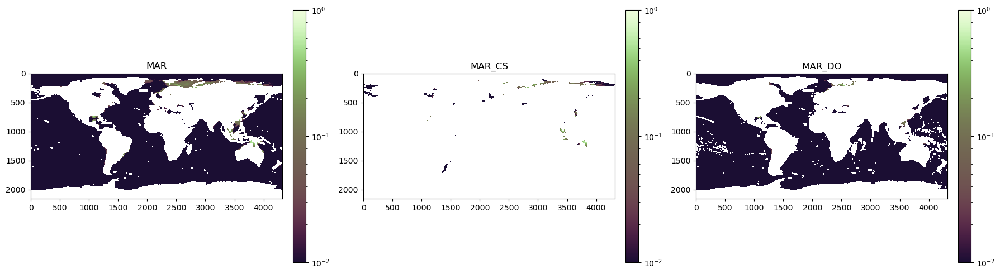

In [14]:
# Get MAR with the CS mask (Continental Shelf)
MAR_CS = np.copy(MAR_plot)
MAR_CS[~np.isnan(dataset_mask)] = np.nan

# Get MAR with the DO mask (Deep Ocean)
MAR_DO = np.copy(MAR_plot)
MAR_DO[np.isnan(dataset_mask)] = np.nan
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

from matplotlib.colors import LogNorm

im0 = axs[0].imshow(MAR/1e3, cmap=cmc.tokyo, norm=LogNorm(vmin=1e-2, vmax=1))
axs[0].set_title("MAR")
plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)

im1 = axs[1].imshow(MAR_CS/1e3, cmap=cmc.tokyo, norm=LogNorm(vmin=1e-2, vmax=1))
axs[1].set_title("MAR_CS")
plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04)

im2 = axs[2].imshow(MAR_DO/1e3, cmap=cmc.tokyo, norm=LogNorm(vmin=1e-2, vmax=1))
axs[2].set_title("MAR_DO")
plt.colorbar(im2, ax=axs[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()




In [15]:
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
print(np.nansum(np.multiply(MAR,area_np*1e10))/1e3)
print("CS")
print(np.nansum(np.multiply(MAR_CS,area_np*1e10))/1e3)
print("DO")
print(np.nansum(np.multiply(MAR_DO,area_np*1e10))/1e3)

3.00911109352638e+16
CS
2.2032203146457496e+16
DO
8060910037669058.0


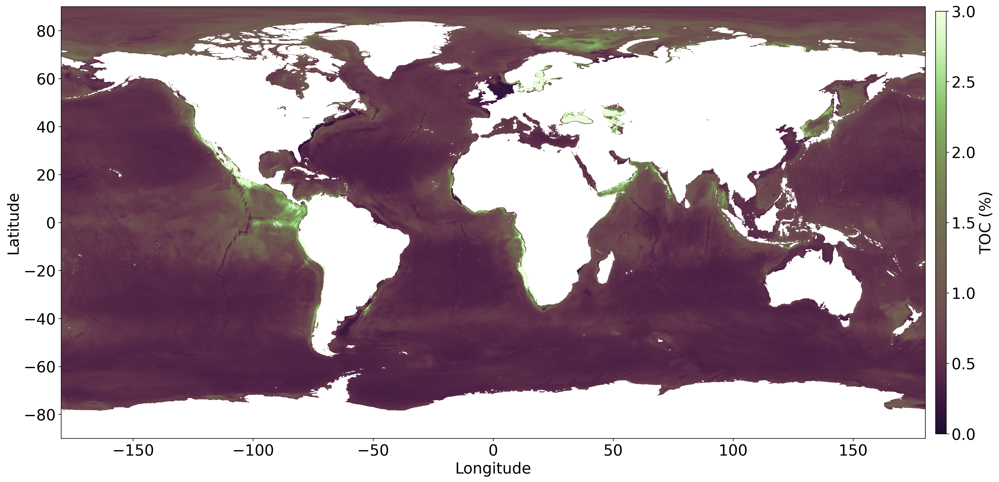

In [16]:
# Read prediction map from xyz files instead of npy files
# Assuming the files have columns: x, y, value and you want a 2D grid
import numpy as np
import pandas as pd

filename = Path().resolve().parents[2] / "nn-toc" / "data" / "output" / "predictionmaps_TOC" / "prediction_map_TOC_supervised_men_CS_noconstraint_v2.npy"
prediction_map_CS = np.load(filename)
prediction_map_DO = np.load(Path().resolve().parents[2] / "nn-toc" / "data" / "output" / "predictionmaps_TOC" / "prediction_map_TOC_noconstraint_DO_v2.npy")

dataset_mask = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of pm_CS
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]

land_file = Path().resolve().parents[2] / "nn-toc-update" / "data" / "raw" / "island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1


pm_overlapped[land_map] = np.nan

toc_overlap = pm_overlapped
# Visualize the overlapped map
VisualiseMap(toc_overlap, cmap=cmc.tokyo, use_log_norm=False, vmin=0, vmax=3, 
             cbar_label="TOC (%)", save_path="../../data/figs/toc.png")


In [17]:
toc_overlap.shape

(2160, 4320)

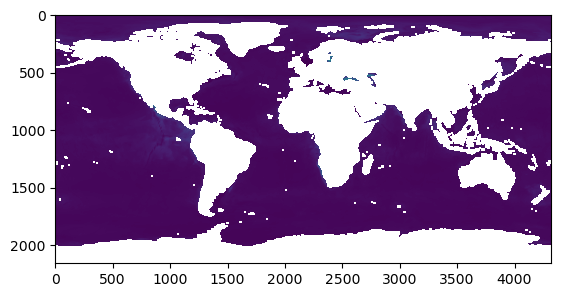

In [18]:
plt.imshow(toc_overlap)

In [19]:
"""

prediction_map_toc_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_toc_entire_MTL_n_2.npy")
prediction_map_toc_CS = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_toc_entire_MTL_n_2.npy")


# Create a copy of prediction_map_DO
toc_overlap = np.copy(prediction_map_toc_DO)

# Mask the values from prediction_map_toc_CS where dataset_mask contains NaN values  
toc_overlap[np.isnan(dataset_mask)] = prediction_map_toc_CS[np.isnan(dataset_mask)]

# Visualize the overlapped map
VisualiseMap(toc_overlap, cmap=cmc.tokyo, use_log_norm=False, vmin=0, vmax=3, 
             cbar_label="TOC (%)", save_path="../../data/figs/toc.png")

"""

'\n\nprediction_map_toc_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_toc_entire_MTL_n_2.npy")\nprediction_map_toc_CS = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_toc_entire_MTL_n_2.npy")\n\n\n# Create a copy of prediction_map_DO\ntoc_overlap = np.copy(prediction_map_toc_DO)\n\n# Mask the values from prediction_map_toc_CS where dataset_mask contains NaN values  \ntoc_overlap[np.isnan(dataset_mask)] = prediction_map_toc_CS[np.isnan(dataset_mask)]\n\n# Visualize the overlapped map\nVisualiseMap(toc_overlap, cmap=cmc.tokyo, use_log_norm=False, vmin=0, vmax=3, \n             cbar_label="TOC (%)", save_path="../../data/figs/toc.png")\n\n'

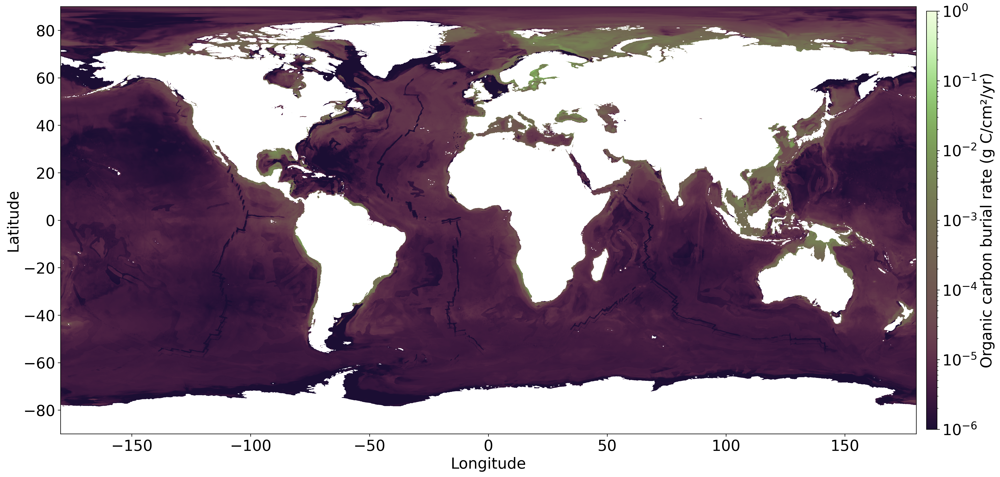

In [25]:
# get the organic carbon burial by multiplying TOC and MAR
# Calculate organic carbon burial rate by multiplying MAR and TOC
# Convert TOC from % to decimal
toc_decimal = toc_overlap / 100
# Multiply MAR (g/cm2/yr) with TOC (decimal) to get organic carbon burial rate (g C/cm2/yr)
organic_carbon_burial = MAR * toc_decimal

small_value = 1e-3  # smaller than vmin=1e-2, but not too small for log scale
organic_carbon_burial = np.where(np.isnan(MAR), np.nan, np.where(organic_carbon_burial <= 0, small_value, organic_carbon_burial))

# Visualize the organic carbon burial rate map
VisualiseMap(organic_carbon_burial/1e3, cmap=cmc.tokyo, use_log_norm=True, vmin=1e-6, vmax=1e0,
             cbar_label="Organic carbon burial rate (g C/cm²/yr)", 
             save_path="../../data/figs/organic_carbon_burial.png")

In [27]:
# Calculate the global organic carbon burial rate (in Tg C/yr)
# area_np is in km², convert to cm²: 1 km² = 1e10 cm²
# organic_carbon_burial is in g C/cm²/yr, so multiply by area in cm² to get g C/yr
# Then sum and convert to Tg (1 Tg = 1e12 g)
global_burial_g = np.nansum(organic_carbon_burial/1e3 * (area_np * 1e10))
print(global_burial_g/1e15)
global_burial_Tg = global_burial_g / 1e12
print(f"Global organic carbon burial rate: {global_burial_Tg:.2f} Tg C/yr")


0.25306767955375686
Global organic carbon burial rate: 253.07 Tg C/yr


In [28]:
# Get MAR with the CS mask (Continental Shelf)
organic_carbon_burial_CS = np.copy(organic_carbon_burial)
organic_carbon_burial_CS[~np.isnan(dataset_mask)] = np.nan

# Get MAR with the DO mask (Deep Ocean)
organic_carbon_burial_DO = np.copy(organic_carbon_burial)
organic_carbon_burial_DO[np.isnan(dataset_mask)] = np.nan
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
print(np.nansum(np.multiply(organic_carbon_burial,area_np*1e10))/1e3/1e12)
print("CS")
print(np.nansum(np.multiply(organic_carbon_burial_CS,area_np*1e10))/1e3/1e12)
print("DO")
print(np.nansum(np.multiply(organic_carbon_burial_DO,area_np*1e10))/1e3/1e12)

253.0676795537563
CS
175.87454155473336
DO
77.1931379990232


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def VisualiseMap(data, cmap, use_log_norm=False, vmin=None, vmax=None, cbar_label=None, 
                 lat_range=None, lon_range=None, save_path = None, show=True, missing_mask=None):
    """
    Visualize a map using matplotlib.

    Parameters:
        data (numpy.ndarray): Array containing the data to be visualized.
        cmap (str or matplotlib.colors.Colormap): Colormap to be used for visualization.
        use_log_norm (bool): Whether to use logarithmic normalization for color scaling.
        vmin (float): Minimum value for color scaling.
        vmax (float): Maximum value for color scaling.
        cbar_label (str): Label for the colorbar.
        lat_range (tuple): Tuple specifying the latitude range (min_lat, max_lat).
        lon_range (tuple): Tuple specifying the longitude range (min_lon, max_lon).
        save_path (str): Path to save the figure. If None, figure is not saved.
        show (bool): Whether to call plt.show() at the end. Default True.
        missing_mask (numpy.ndarray): Boolean mask for missing ocean areas to be shown in gray.
    """
    plt.figure(figsize=(20, 10), dpi=300)
    
    if lat_range and lon_range:
        min_lat, max_lat = lat_range
        min_lon, max_lon = lon_range
        
        # Calculate the indices corresponding to the specified latitude and longitude ranges
        lat_indices = np.linspace(90, -90, data.shape[0])
        lon_indices = np.linspace(-180, 180, data.shape[1])
        
        lat_mask = (lat_indices >= min_lat) & (lat_indices <= max_lat)
        lon_mask = (lon_indices >= min_lon) & (lon_indices <= max_lon)
        
        # Ensure that the mask applies correctly to the data
        data_snippet = data[np.ix_(lat_mask, lon_mask)]
        extent = [min_lon, max_lon, min_lat, max_lat]
        if missing_mask is not None:
            missing_mask_snippet = missing_mask[np.ix_(lat_mask, lon_mask)]
        else:
            missing_mask_snippet = None
    else:
        data_snippet = data
        extent = [-180, 180, -90, 90]
        missing_mask_snippet = missing_mask
    # Overlay missing ocean mask as gray
    if missing_mask_snippet is not None:
        # Create a gray overlay for missing ocean areas
        gray_overlay = np.ma.masked_array(np.ones_like(missing_mask_snippet, dtype=float) * 0.5,
                                          mask=~missing_mask_snippet)
        plt.imshow(gray_overlay, cmap='gray', vmin=0, vmax=1, alpha=0.7, extent=extent)
    
    if use_log_norm:
        norm = LogNorm(vmin=vmin, vmax=vmax)
        plt.imshow(data_snippet, cmap=cmap, norm=norm, extent=extent)
    else:
        plt.imshow(data_snippet, cmap=cmap, vmin=vmin, vmax=vmax, extent=extent)
    
    
    cbar = plt.colorbar(label=cbar_label, aspect=40, pad=0.01, shrink=0.8)
    cbar.ax.tick_params(labelsize=20)
    cbar.set_label(cbar_label, fontsize=20)
    
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.xlabel("Longitude", fontsize=20)
    plt.ylabel("Latitude", fontsize=20)
    plt.tight_layout()
    if save_path != None :
        plt.savefig(save_path, dpi = 200)
    if show:
        plt.show()



In [32]:

# Load Jorgenson TOU map
jorgenson_TOU_map = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/TOU_Jorgenson2022.nc"
jorgenson_data = xr.open_dataset(jorgenson_TOU_map)
tou_data = jorgenson_data.variables['data']
tou_data =  np.rot90(np.rot90(np.fliplr(tou_data)))


missing_ocean_mask = np.isnan(tou_carbon) & (~land_map)


# Create a mask for invalid (-1) values
invalid_mask = tou_data < 0


# Get valid data points
valid_points = ~invalid_mask
valid_values = tou_data[valid_points]

# Get coordinates of valid and invalid points
y_coords, x_coords = np.indices(tou_data.shape)
valid_coords = np.column_stack((y_coords[valid_points], x_coords[valid_points]))
invalid_coords = np.column_stack((y_coords[invalid_mask], x_coords[invalid_mask]))

# Interpolate invalid points using nearest neighbor interpolation
from scipy.interpolate import NearestNDInterpolator
interpolator = NearestNDInterpolator(valid_coords, valid_values)
#tou_data[invalid_mask] = interpolator(invalid_coords)
tou_data[invalid_mask] = np.nan
tou_data[land_map] = np.nan
# Plot the TOU map
VisualiseMap(tou_data, cmap='viridis', use_log_norm=True, vmin=1e-3, vmax=119, cbar_label='TOU (mmol O2 m⁻² d⁻¹)', missing_mask = missing_ocean_mask)


# Convert TOU from mmol O2 m-2 d-1 to C mmol m-2 yr-1
# Get elevation data
elevation_file = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"
elevation_data = xr.open_dataset(elevation_file).variables['data'].to_numpy()
elevation_data = np.rot90(np.rot90(np.fliplr(elevation_data)))

# Create depth masks for different regions
inner_shelf_0_10 = (elevation_data <= 0) & (elevation_data > -10)
inner_shelf_10_50 = (elevation_data <= -10) & (elevation_data > -50) 
outer_shelf = (elevation_data <= -50) & (elevation_data > -200)
slope_200_1000 = (elevation_data <= -200) & (elevation_data > -1000)
slope_1000_2000 = (elevation_data <= -1000) & (elevation_data > -2000)
rise = (elevation_data <= -2000) & (elevation_data > -4000)
abyss = elevation_data <= -4000

# Apply different RQ ratios based on depth
tou_carbon = np.zeros_like(tou_data) * np.nan
tou_carbon[inner_shelf_0_10] = tou_data[inner_shelf_0_10] * 365 * 0.90  # RQ = 0.90
tou_carbon[inner_shelf_10_50] = tou_data[inner_shelf_10_50] * 365 * 0.90  # RQ = 0.90
tou_carbon[outer_shelf] = tou_data[outer_shelf] * 365 * 0.85  # RQ = 0.85
tou_carbon[slope_200_1000] = tou_data[slope_200_1000] * 365 * 0.80  # RQ = 0.80
tou_carbon[slope_1000_2000] = tou_data[slope_1000_2000] * 365 * 0.80  # RQ = 0.80
tou_carbon[rise] = tou_data[rise] * 365 * 0.75  # RQ = 0.75
tou_carbon[abyss] = tou_data[abyss] * 365 * 0.75  # RQ = 0.75

# Convert from mmol C m-2 yr-1 to g C m-2 yr-1
# Molar mass of carbon = 12.01 g/mol
tou_carbon_g = tou_carbon * 12.01 / 1000  # Convert mmol to g
tou_carbon_g[land_map] = np.nan
#missing_ocean_mask = np.isnan(tou_carbon_g) & (~land_map)
# Plot the converted TOU map
VisualiseMap(tou_carbon_g, cmap='viridis', use_log_norm=True, vmin=1e-1, vmax=500,
             cbar_label='Carbon degradation rate (g C m⁻² yr⁻¹)', missing_mask =  missing_ocean_mask)




NameError: name 'tou_carbon' is not defined

In [ ]:
plt.imshow(missing_ocean_mask)

In [ ]:

# Load Jorgenson TOU map
jorgenson_TOU_map = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/TOU_Jorgenson2022.nc"
jorgenson_data = xr.open_dataset(jorgenson_TOU_map)
tou_data = jorgenson_data.variables['data']
tou_data =  np.rot90(np.rot90(np.fliplr(tou_data)))

# Create a mask for invalid (-1) values
invalid_mask = tou_data < 0

# Get valid data points
valid_points = ~invalid_mask
valid_values = tou_data[valid_points]

# Get coordinates of valid and invalid points
y_coords, x_coords = np.indices(tou_data.shape)
valid_coords = np.column_stack((y_coords[valid_points], x_coords[valid_points]))
invalid_coords = np.column_stack((y_coords[invalid_mask], x_coords[invalid_mask]))

# Interpolate invalid points using nearest neighbor interpolation
from scipy.interpolate import NearestNDInterpolator
interpolator = NearestNDInterpolator(valid_coords, valid_values)
#tou_data[invalid_mask] = interpolator(invalid_coords)
tou_data[invalid_mask] = np.nan
tou_data[land_map] = np.nan
# Plot the TOU map
VisualiseMap(tou_data, cmap='viridis', use_log_norm=True, vmin=1e-3, vmax=119, cbar_label='TOU (mmol O2 m⁻² d⁻¹)', missing_mask = missing_ocean_mask)

# Convert TOU from mmol O2 m-2 d-1 to C mmol m-2 yr-1
# Get elevation data
elevation_file = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"
elevation_data = xr.open_dataset(elevation_file).variables['data'].to_numpy()
elevation_data = np.rot90(np.rot90(np.fliplr(elevation_data)))

# Create depth masks for different regions
inner_shelf_0_10 = (elevation_data <= 0) & (elevation_data > -10)
inner_shelf_10_50 = (elevation_data <= -10) & (elevation_data > -50) 
outer_shelf = (elevation_data <= -50) & (elevation_data > -200)
slope_200_1000 = (elevation_data <= -200) & (elevation_data > -1000)
slope_1000_2000 = (elevation_data <= -1000) & (elevation_data > -2000)
rise = (elevation_data <= -2000) & (elevation_data > -4000)
abyss = elevation_data <= -4000

# Find the area of different regions of the oceans, masking invalid points
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
area_masked = np.copy(area_np)
area_masked[invalid_mask] = np.nan

area_inner_shelf_0_10 = np.nansum(area_masked[inner_shelf_0_10])
area_inner_shelf_10_50 = np.nansum(area_masked[inner_shelf_10_50])
area_outer_shelf = np.nansum(area_masked[outer_shelf])
area_slope_200_1000 = np.nansum(area_masked[slope_200_1000])
area_slope_1000_2000 = np.nansum(area_masked[slope_1000_2000])
area_rise = np.nansum(area_masked[rise])
area_abyss = np.nansum(area_masked[abyss])

print("Area of inner shelf (0-10 m):", area_inner_shelf_0_10/1e6, "10^6 km²")
print("Area of inner shelf (10-50 m):", area_inner_shelf_10_50/1e6, "10^6 km²")
print("Area of outer shelf (50-200 m):", area_outer_shelf/1e6, "10^6 km²")
print("Area of slope (200-1000 m):", area_slope_200_1000/1e6, "10^6 km²")
print("Area of slope (1000-2000 m):", area_slope_1000_2000/1e6, "10^6 km²")
print("Area of rise (2000-4000 m):", area_rise/1e6, "10^6 km²")
print("Area of abyss (>4000 m):", area_abyss/1e6, "10^6 km²")

# Apply different RQ ratios based on depth
tou_carbon = np.zeros_like(tou_data) * np.nan
tou_carbon[inner_shelf_0_10] = tou_data[inner_shelf_0_10] * 365 * 0.90  # RQ = 0.90
tou_carbon[inner_shelf_10_50] = tou_data[inner_shelf_10_50] * 365 * 0.90  # RQ = 0.90
tou_carbon[outer_shelf] = tou_data[outer_shelf] * 365 * 0.85  # RQ = 0.85
tou_carbon[slope_200_1000] = tou_data[slope_200_1000] * 365 * 0.80  # RQ = 0.80
tou_carbon[slope_1000_2000] = tou_data[slope_1000_2000] * 365 * 0.80  # RQ = 0.80
tou_carbon[rise] = tou_data[rise] * 365 * 0.75  # RQ = 0.75
tou_carbon[abyss] = tou_data[abyss] * 365 * 0.75  # RQ = 0.75

# Convert from mmol C m-2 yr-1 to g C m-2 yr-1
# Molar mass of carbon = 12.01 g/mol
tou_carbon_g = tou_carbon * 12.01 / 1000  # Convert mmol to g
tou_carbon_g[land_map] = np.nan
# Plot the converted TOU map
VisualiseMap(tou_carbon_g, cmap='viridis', use_log_norm=True, vmin=1e-1, vmax=500,
             cbar_label='Carbon degradation rate (g C m⁻² yr⁻¹)', missing_mask = missing_ocean_mask)


In [ ]:
# Get MAR with the CS mask (Continental Shelf)
tou_carbon_g_CS = np.copy(tou_carbon_g)
tou_carbon_g_CS[~np.isnan(dataset_mask)] = np.nan

# Get MAR with the DO mask (Deep Ocean)
tou_carbon_g_DO = np.copy(tou_carbon_g)
tou_carbon_g_DO[np.isnan(dataset_mask)] = np.nan
area_np = np.array(area) # in km²:  10^6 m² = 1 km²
print(np.nansum(np.multiply(tou_carbon_g,area_np*1e6))/1e12)
print("CS")
print(np.nansum(np.multiply(tou_carbon_g_CS,area_np*1e6))/1e12)
print ("DO")
print(np.nansum(np.multiply(tou_carbon_g_DO,area_np*1e6))/1e12)

In [ ]:
"""
# Load Jorgenson TOU map
jorgenson_TOU_map = "/gxfs_work/cau/sunms498/TOU_global_SAR_5arcmin_2160x4320.nc"
jorgenson_data = xr.open_dataset(jorgenson_TOU_map)
tou_data = jorgenson_data.variables['SAR']
tou_data =  np.rot90(np.rot90(np.fliplr(tou_data)))
# Create a mask for invalid (-1) values
invalid_mask = tou_data < 0

# Get valid data points
valid_points = ~invalid_mask
valid_values = tou_data[valid_points]

# Get coordinates of valid and invalid points
y_coords, x_coords = np.indices(tou_data.shape)
valid_coords = np.column_stack((y_coords[valid_points], x_coords[valid_points]))
invalid_coords = np.column_stack((y_coords[invalid_mask], x_coords[invalid_mask]))

# Interpolate invalid points using nearest neighbor interpolation
from scipy.interpolate import NearestNDInterpolator
interpolator = NearestNDInterpolator(valid_coords, valid_values)
tou_data[invalid_mask] = interpolator(invalid_coords)

# Plot the TOU map
#plt.imshow(tou_data, cmap='viridis', norm=LogNorm(vmin=1e-3, vmax=119))

# Convert TOU from mmol O2 m-2 d-1 to C mmol m-2 yr-1
# Using Redfield ratio O2:C = 138:106
tou_carbon = tou_data * 365  # Convert to annual rate and apply Redfield ratio#(106/138)

# Convert from mmol C m-2 yr-1 to g C m-2 yr-1
# Molar mass of carbon = 12.01 g/mol
tou_carbon_g = tou_carbon * 12.01 / 1000  # Convert mmol to g
tou_carbon_g[land_map] = np.nan
# Plot the converted TOU map
VisualiseMap(tou_carbon_g, cmap='viridis', use_log_norm=True, vmin=1e-1, vmax=500,
             cbar_label='Carbon degradation rate (g C m⁻² yr⁻¹)')

"""


In [ ]:
# Calculate rain rate by summing degraded carbon (TOU) and buried carbon
rain_rate = tou_carbon_g + organic_carbon_burial*1e4/1e3

# Plot the rain rate map
VisualiseMap(rain_rate, cmap='viridis', use_log_norm=True, vmin=1e-1, vmax=500,
             cbar_label='Carbon rain rate (g C m⁻² yr⁻¹)',
             save_path="../../data/figs/carbon_rain_rate.png", missing_mask = missing_ocean_mask)


In [ ]:
# Calculate the global organic carbon burial rate (in Tg C/yr)
# area_np is in km², convert to cm²: 1 km² = 1e10 cm²
# organic_carbon_burial is in g C/cm²/yr, so multiply by area in cm² to get g C/yr
# Then sum and convert to Tg (1 Tg = 1e12 g)
global_rain_rate_g = np.nansum(rain_rate * (area_np * 1e10))
print(global_rain_rate_g/1e16)
global_rain_rate_Pg = global_rain_rate_g / 1e15
print(f"Global rain rate: {global_rain_rate_Pg:.2f} Pg C/yr")


In [ ]:
# Get MAR with the CS mask (Continental Shelf)
rain_rate_CS = np.copy(rain_rate)
rain_rate_CS[~np.isnan(dataset_mask)] = np.nan

# Get MAR with the DO mask (Deep Ocean)
rain_rate_DO = np.copy(rain_rate)
rain_rate_DO[np.isnan(dataset_mask)] = np.nan
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
print(np.nansum(np.multiply(rain_rate,area_np*1e6))/1e12)
print("CS")
print(np.nansum(np.multiply(rain_rate_CS,area_np*1e6))/1e12)
print("DO")
print(np.nansum(np.multiply(rain_rate_DO,area_np*1e6))/1e12)

In [ ]:
# Calculate burial efficiency as the ratio of organic carbon burial to rain rate
# Avoid division by zero by masking invalid values
burial_efficiency = np.full_like(rain_rate, np.nan)
valid_mask = rain_rate > 0
burial_efficiency[valid_mask] = organic_carbon_burial[valid_mask]*10 / rain_rate[valid_mask]


# Optionally, plot the burial efficiency map
VisualiseMap(burial_efficiency, cmap='viridis', use_log_norm=True, vmin=1e-4, vmax=10,
             cbar_label='Burial Efficiency (fraction)',
             save_path="../../data/figs/burial_efficiency.png", missing_mask = missing_ocean_mask)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binned_statistic
from scipy.interpolate import splprep, splev

# Convert MAR from g/m2/yr to g/cm2/yr
MAR_cm2 = MAR / 1e3

# Flatten the arrays and remove NaNs for correlation plotting
burial_eff_flat = burial_efficiency.flatten() * 100  # keep percentage
mar_flat = MAR_cm2.flatten()  # MAR in g/cm2/yr

# Mask out NaN values in either array and ensure positive values for log scale
valid_mask = (
    ~np.isnan(burial_eff_flat) & 
    ~np.isnan(mar_flat) & 
    (burial_eff_flat > 0) & 
    (mar_flat > 0)
)
burial_eff_valid = burial_eff_flat[valid_mask]
mar_valid = mar_flat[valid_mask]

# Define bin edges in log space for the polyline and distribution
x_min, x_max = 1e-4, 20  # adjust min MAR for g/cm2/yr
y_min, y_max = 1e-1, np.nanmax(burial_eff_valid)
n_bins = 30
x_bins = np.logspace(np.log10(x_min), np.log10(x_max), n_bins+1)
x_bin_centers = np.sqrt(x_bins[:-1] * x_bins[1:])

# Compute median and percentiles of burial efficiency in each MAR bin
medians, _, _ = binned_statistic(mar_valid, burial_eff_valid, statistic='median', bins=x_bins)
means, _, _ = binned_statistic(mar_valid, burial_eff_valid, statistic='mean', bins=x_bins)
p16, _, _ = binned_statistic(mar_valid, burial_eff_valid, statistic=lambda y: np.percentile(y, 16) if len(y) > 0 else np.nan, bins=x_bins)
p84, _, _ = binned_statistic(mar_valid, burial_eff_valid, statistic=lambda y: np.percentile(y, 84) if len(y) > 0 else np.nan, bins=x_bins)

# --- Polygon definition and smoothing (from file_context_0) ---
polygon_points = [
    (0.00014173179439636737, 1.4974252759440378), (0.00012416732166530914, 1.2815841937148995),
    (0.00011469152568937151, 1.0075752236373388), (0.00011776692203322792, 0.8148888310443317),
    (0.00013803057307913003, 0.6876304086102258), (0.00017984370274754958, 0.588514349897696),
    (0.0002604852628224605, 0.5036850257037295), (0.00040845767719612083, 0.4692806728003228),
    (0.0007708234706472447, 0.47596820504348125), (0.0012087008721234963, 0.5330158662488613),
    (0.0017506799489709444, 0.6054072331120912), (0.0022810074415059453, 0.6779689428227432),
    (0.0028943740254068102, 0.8870947541826129), (0.0037711568549895044, 1.0968547626153815),
    (0.0043046175180337706, 1.4150248357731663), (0.0049135405100021465, 1.9872414871681794),
    (0.0056086005881563076, 2.5276696164235144), (0.007307594792262904, 3.6517197425281225),
    (0.008564981402176057, 5.350813882235199), (0.011766041005620521, 7.621697400247265),
    (0.015741361640959343, 9.69440959670781), (0.027439372775148945, 12.33079358748768),
    (0.05317090359934047, 13.423404383086744), (0.1030324203376406, 14.821071199103464),
    (0.16589366502430378, 15.684139294966705), (0.2050056155549369, 19.66912676331274),
    (0.2050056155549369, 25.736251425383497), (0.267107265897565, 33.20169286568543),
    (0.43007242913597854, 41.637497184261605), (0.7300985581839751, 45.972861481991956),
    (1.4147553726292088, 48.64997634687758), (2.5322421275128675, 52.96076859111526),
    (4.778736633493171, 56.843479041924034), (6.921512674158655, 64.5636566307559),
    (8.112467783772267, 74.37737760911573), (5.905396357242883, 84.47891561157468),
    (3.7660418889583314, 84.47891561157468), (1.9956173894076663, 79.83020295567067),
    (1.0029641829174964, 75.43730003880883), (0.5603527999634317, 70.28453320999704),
    (0.26013195657660776, 68.3233600585112), (0.12732387792106806, 62.762115037420266),
    (0.06746864542613525, 56.04480678844559), (0.03974313317520659, 50.759631000138434),
    (0.024038878786350634, 41.637497184261605), (0.016596873558192154, 35.63580708463516),
    (0.01086811873010988, 28.82089644253885), (0.006749917648247854, 22.340482461264035),
    (0.004538564978857279, 17.317197527048197), (0.0024694639207914837, 12.33079358748768),
    (0.0017049622328128447, 9.291493816720058), (0.0010589095454925283, 7.304926985069622),
    (0.0007708234706472447, 5.824940463909878), (0.0005182926060837099, 4.389206413940802),
    (0.00033053017057096257, 3.169893684708807), (0.00021644083297095285, 2.1941563206009165),
    (0.0001661189786257998, 1.7496177528036005)
]
polygon_points = np.array(polygon_points)

# Rescale polygon x-values from g/m2/yr to g/cm2/yr
x_poly = polygon_points[:, 0]   # convert from g/m2/yr to g/cm2/yr
y_poly = polygon_points[:, 1]
if np.allclose(polygon_points[0], polygon_points[-1]):
    x_poly = x_poly[:-1]
    y_poly = y_poly[:-1]

# Interpolate in log-log space for better smoothing
logx = np.log10(x_poly)
logy = np.log10(y_poly)
tck, u = splprep([logx, logy], s=0.005, per=True)
unew = np.linspace(0, 1, 400)
out = splev(unew, tck)
x_smooth = 10**np.array(out[0])
y_smooth = 10**np.array(out[1])

# --- Plot 1: Data, histogram, polyline, and polygon envelope ---
plt.figure(figsize=(8, 8), dpi = 300)
#plt.scatter(mar_valid, burial_eff_valid, alpha=0.3, s=5, label='Data points')

# 2D histogram (rectangular bins)
hist, xedges, yedges, img = plt.hist2d(
    mar_valid, burial_eff_valid, 
    bins=[np.logspace(np.log10(x_min), np.log10(x_max), 100), np.logspace(np.log10(y_min), np.log10(y_max), 100)], 
    cmap=cmc.imola, 
    norm='log', 
    alpha=0.8
)
cb = plt.colorbar(img, label='log10(N points per bin)')

# Polyline (median) and fill between percentiles
plt.plot(x_bin_centers, means, color='black', lw=2, label='Mean')
plt.fill_between(x_bin_centers, p16, p84, color='black', alpha=0.2, label='Mean ± 1 std')

# Plot the smoothed envelope polygon
plt.fill(x_smooth, y_smooth, color='red', alpha=0.15, label='Envelope (O$_2$ > 20 μM, Dale et. al. (2015))', zorder=1)
plt.plot(x_smooth, y_smooth, 'r-', lw=2, zorder=2)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('MAR (g/cm²/yr)')
plt.ylabel('Burial Efficiency (%)')
#plt.title('Burial Efficiency percentage vs. MAR (g/cm²/yr)')
plt.grid(True, which='both', ls='--', lw=0.5)
plt.legend()
plt.xlim(x_min, x_max)

# Make the plot square by setting equal axis lengths (square plot)
plt.gcf().set_size_inches(6, 6)  # Set the figure to be square

plt.show()


In [ ]:
means

In [ ]:
medians

In [ ]:
#restrepo_features_path = Path(\/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/\)
#restrepo_features_path = Path(\/gxfs_work/cau/sunms498/work_old/Data/Features_PhrampusLee_noNaN_highres_rot/\)
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    #print(filenames)
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

file_idx = -1
corrupted_files = 0
bottomOxygen = None  # Initialize bottomOxygen variable

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1

    if file == "SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.5m.grd":
        bottomOxygen_fileidx = file_idx
        print(bottomOxygen_fileidx)
        
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        except Exception as e:
            # If you have arrays to append to, uncomment below
            # restrepo_X_mean = np.append(restrepo_X_mean, np.nan)
            # restrepo_X_std = np.append(restrepo_X_std, np.nan)
            corrupted_files += 1
            continue
        dataset_numpy_bottomOxygen = rootgrp.variables['data']
        bottomOxygen = np.array(dataset_numpy_bottomOxygen)
        break  # Stop after finding and loading bottomOxygen
bottomOxygen = np.rot90(np.rot90(np.fliplr(bottomOxygen)))
valid_mask = valid_mask.reshape([2160,4320])
# At the end, plot bottomOxygen for the valid mask using VisualiseMap
if bottomOxygen is not None and 'valid_mask' in locals():
    bottomOxygen_masked = np.full_like(bottomOxygen, np.nan)
    bottomOxygen_masked[valid_mask] = bottomOxygen[valid_mask]
    VisualiseMap(
        bottomOxygen_masked,
        cmap='viridis',
        use_log_norm=False,
        vmin=np.nanmin(bottomOxygen_masked),
        vmax=np.nanmax(bottomOxygen_masked),
        cbar_label='Bottom water oxygen (mL/L)',
        save_path=None
    )

In [ ]:
#restrepo_features_path = Path(\/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/\)
#restrepo_features_path = Path(\/gxfs_work/cau/sunms498/work_old/Data/Features_PhrampusLee_noNaN_highres_rot/\)
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    #print(filenames)
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

file_idx = -1
corrupted_files = 0
bottomOxygen = None  # Initialize bottomOxygen variable

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1

    if file == "SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.5m.grd":
        bottomOxygen_fileidx = file_idx
        print(bottomOxygen_fileidx)
        
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        except Exception as e:
            # If you have arrays to append to, uncomment below
            # restrepo_X_mean = np.append(restrepo_X_mean, np.nan)
            # restrepo_X_std = np.append(restrepo_X_std, np.nan)
            corrupted_files += 1
            continue
        dataset_numpy_bottomOxygen = rootgrp.variables['data']
        bottomOxygen = np.array(dataset_numpy_bottomOxygen)
        break  # Stop after finding and loading bottomOxygen

bottomOxygen = np.rot90(np.rot90(np.fliplr(bottomOxygen)))
# Convert from mL/L to μmol/kg
# 1 mL/L O2 ≈ 44.661 μmol/kg at 0°C, S=35 PSU (approximate, see Garcia & Gordon 1992)
bottomOxygen_umolkg = bottomOxygen * 44.661

valid_mask = valid_mask.reshape([2160,4320])
# At the end, plot bottomOxygen for the valid mask using VisualiseMap
if bottomOxygen is not None and 'valid_mask' in locals():
    bottomOxygen_masked = np.full_like(bottomOxygen_umolkg, np.nan)
    bottomOxygen_masked[valid_mask] = bottomOxygen_umolkg[valid_mask]
    VisualiseMap(
        bottomOxygen_masked,
        cmap='viridis',
        use_log_norm=False,
        vmin=np.nanmin(bottomOxygen_masked),
        vmax=np.nanmax(bottomOxygen_masked),
        cbar_label='Bottom water oxygen (μmol/kg)',
        save_path=None
    )

In [ ]:
# Load bottom water oxygen from the Restrepo features
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)
restrepo_files.sort()

oxygen = None
for file in restrepo_files:
    if file == "SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.5m.grd":
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format='NETCDF4')
            dataset_numpy_oxygen = rootgrp.variables['data']
            oxygen = np.array(dataset_numpy_oxygen)
        except Exception as e:
            oxygen = None
        break

if oxygen is not None:
    oxygen = np.rot90(np.rot90(np.fliplr(oxygen)))
    # Only plot for valid_mask (where burial_eff_valid and mar_valid are defined)
    if 'valid_mask' in locals():
        oxygen_valid = oxygen[valid_mask]
        oxygen_flat = oxygen_valid.flatten()
        print(oxygen_flat.shape)
        print(burial_eff_valid.shape)
        # Remove NaNs and nonpositive values for log-log plot
        mask = (
            ~np.isnan(burial_eff_valid) &
            ~np.isnan(oxygen_valid) &
            (burial_eff_valid > 0) &
            (oxygen_valid > 0)
        )
        x = oxygen_valid[mask]
        y = burial_eff_valid[mask]
        # Define bin edges in log space
        x_min, x_max = 7e-1, np.nanmax(x)
        y_min, y_max = 7e-1, np.nanmax(y)
        x_bins = np.logspace(np.log10(x_min), np.log10(x_max), 100)
        y_bins = np.logspace(np.log10(y_min), np.log10(y_max), 100)
        # 2D histogram (rectangular bins)
        plt.figure(figsize=(8, 6))
        hist, xedges, yedges, img = plt.hist2d(
            x, y,
            bins=[x_bins, y_bins],
            cmap='Reds',
            norm='log',
            alpha=0.7
        )
        cb = plt.colorbar(img, label='log10(N points per bin)')
        plt.xscale('log')
        plt.yscale('log')
        plt.xlabel('Bottom water O$_2$ (mmol/L, log scale)')
        plt.ylabel('Burial Efficiency (%) (log scale)')
        plt.title('Burial Efficiency vs. Bottom Water Oxygen')
        plt.grid(True, which='both', ls='--', lw=0.5)
        plt.xlim(left=x_min)
        plt.ylim(bottom=y_min)

        # --- Add polyline with distribution (mean and shaded std) ---
        # Bin the x (oxygen) axis logarithmically
        from scipy.stats import binned_statistic

        n_poly_bins = 30
        poly_bins = np.logspace(np.log10(x_min), np.log10(x_max), n_poly_bins+1)
        bin_centers = np.sqrt(poly_bins[:-1] * poly_bins[1:])  # geometric mean for log bins

        # Compute mean and std of y in each x bin
        y_mean, _, _ = binned_statistic(x, y, statistic='mean', bins=poly_bins)
        y_std, _, _ = binned_statistic(x, y, statistic='std', bins=poly_bins)
        counts, _, _ = binned_statistic(x, y, statistic='count', bins=poly_bins)

        # Only plot where there are enough points in the bin
        min_count = 10
        valid = counts >= min_count

        # Plot the polyline (mean) and shaded region (std)
        plt.plot(bin_centers[valid], y_mean[valid], color='black', lw=2, label='Mean')
        plt.fill_between(
            bin_centers[valid],
            y_mean[valid] - y_std[valid],
            y_mean[valid] + y_std[valid],
            color='black',
            alpha=0.2,
            label='Mean ± 1 std'
        )

        plt.legend()
        plt.show()

In [ ]:
from scipy.stats import binned_statistic

plt.figure(figsize=(8, 6), dpi = 300)
y_be = burial_eff_valid[mask]
x_mgL = oxygen_valid[mask]

# --- Density background using 2D histogram (mg/L) ---
x_min, x_max = np.nanmin(x_mgL), np.nanmax(x_mgL)
y_min, y_max = np.nanmin(y_be), np.nanmax(y_be)
x_min = max(x_min, 0.07)  # avoid zeros
y_min = max(y_min, 1e-2)

# Ensure the global mean reaches down to 1e-1
x_min_for_bins = 1e-1

# 2D histogram bins for density
x_bins = np.logspace(np.log10(x_min_for_bins), np.log10(x_max), 40)
y_bins = np.logspace(np.log10(y_min), np.log10(y_max), 40)
hist, xedges, yedges, img = plt.hist2d(
    x_mgL, y_be,
    bins=[x_bins, y_bins],
    cmap="Greys", norm="log", alpha=0.5
)
cb = plt.colorbar(img, label="log10(N points per bin)")

# --- Draw vertical lines splitting the different regions ---
region_boundaries = [0.5, 2, 6]  # mg/L boundaries between regions
for xb in region_boundaries:
    plt.axvline(x=xb, color='k', linestyle='--', lw=1.5, alpha=0.7, zorder=10)
    plt.text(xb, y_max*0.95, f'{xb} mg/L', rotation=90, va='top', ha='right', color='k', fontsize=10, alpha=0.7)

# --- Global trend line (mg/L) ---
n_bins_global = 20
# Extend the bins down to 1e-1
bins_global = np.logspace(np.log10(1e-1), np.log10(x_max), n_bins_global + 1)
bin_centers_global = np.sqrt(bins_global[:-1] * bins_global[1:])
y_mean_global, _, _ = binned_statistic(x_mgL, y_be, statistic='mean', bins=bins_global)
y_std_global, _, _ = binned_statistic(x_mgL, y_be, statistic='std', bins=bins_global)
counts_global, _, _ = binned_statistic(x_mgL, y_be, statistic='count', bins=bins_global)
valid_global = counts_global >= 0

plt.plot(bin_centers_global[valid_global], y_mean_global[valid_global],
         color='black', lw=2, label='Global Mean')
plt.fill_between(bin_centers_global[valid_global],
                 y_mean_global[valid_global] - y_std_global[valid_global],
                 y_mean_global[valid_global] + y_std_global[valid_global],
                 color='black', alpha=0.2)

# --- Regions (now directly in mg/L, and restrict to region boundaries) ---
regions = [
    {"name": "Anoxic (<0.5 mg/L)", "mask": anoxic_mask, "color": "red", "scatter": True, "xmin": x_min_for_bins, "xmax": 0.5},
    # Hypoxic region: ensure the yellow line and region extend from 0.5 to 2 mg/L
    {"name": "Hypoxic (0.5–2 mg/L)", "mask": hypoxic_mask, "color": "orange", "scatter": False, "xmin": 0.5, "xmax": 2.0},
    {"name": "Intermediate (2–6 mg/L)", "mask": intermediate_mask, "color": "green", "scatter": False, "xmin": 2, "xmax": 6},
    {"name": "Normal (>6 mg/L)", "mask": normal_mask, "color": "blue", "scatter": False, "xmin": 6, "xmax": x_max},
]

for region in regions:
    x_r = x_mgL[region["mask"]]
    y_r = y_be[region["mask"]]
    # Restrict to region boundaries
    x_r_mask = (x_r >= region["xmin"]) & (x_r < region["xmax"])
    x_r = x_r[x_r_mask]
    y_r = y_r[x_r_mask]
    valid = (~np.isnan(x_r)) & (~np.isnan(y_r)) & (x_r > 0) & (y_r > 0)
    x_r = x_r[valid]
    y_r = y_r[valid]
    if len(x_r) == 0:
        continue

    # scatter for anoxic & hypoxic
    if region["scatter"]:
        plt.scatter(x_r, y_r, s=8, alpha=0.5, color=region["color"], label=f"{region['name']} Points")

    # trend line
    n_bins = 8
    # Only create bins if x_r has a range
    if np.min(x_r) < np.max(x_r):
        # For the hypoxic region, ensure bins span exactly from 0.5 to 2 mg/L
        if region["name"].startswith("Hypoxic"):
            bins_r = np.logspace(np.log10(0.5), np.log10(2.0), n_bins + 1)
        else:
            bins_r = np.logspace(np.log10(np.min(x_r)), np.log10(np.max(x_r)), n_bins + 1)
        bin_centers_r = np.sqrt(bins_r[:-1] * bins_r[1:])
        y_mean_r, _, _ = binned_statistic(x_r, y_r, statistic='mean', bins=bins_r)
        y_std_r, _, _ = binned_statistic(x_r, y_r, statistic='std', bins=bins_r)
        counts_r, _, _ = binned_statistic(x_r, y_r, statistic='count', bins=bins_r)
        valid_r = counts_r >= 5

        plt.plot(bin_centers_r[valid_r], y_mean_r[valid_r],
                 color=region["color"], lw=2, label=f'{region["name"]} Mean')
        plt.fill_between(bin_centers_r[valid_r],
                         y_mean_r[valid_r] - y_std_r[valid_r],
                         y_mean_r[valid_r] + y_std_r[valid_r],
                         color=region["color"], alpha=0.2)

# --- Finalize ---
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Bottom water O$_2$ (mg/L, log scale)')
plt.ylabel('Burial Efficiency (%) (log scale)')
#plt.title('Burial Efficiency vs. Bottom Water Oxygen (mg/L)\nGlobal & Regional Trends')
plt.grid(True, which='both', ls='--', lw=0.5)
plt.xlim(x_min_for_bins, x_max)
plt.ylim(y_min, y_max)
plt.legend()
plt.show()

In [ ]:
from scipy.stats import binned_statistic

plt.figure(figsize=(8, 6))

# --- Global density background (mg/L) ---
x_min, x_max = np.nanmin(x_mgL), np.nanmax(x_mgL)
y_min, y_max = np.nanmin(y_be), np.nanmax(y_be)
x_min = max(x_min, 0.07)  # avoid zeros
y_min = max(y_min, 1e-2)

x_bins = np.logspace(np.log10(x_min), np.log10(x_max), 60)
y_bins = np.logspace(np.log10(y_min), np.log10(y_max), 60)

hist, xedges, yedges, img = plt.hist2d(
    x_mgL, y_be,
    bins=[x_bins, y_bins],
    cmap="Greys", norm="log", alpha=0.5
)
cb = plt.colorbar(img, label="log10(N points per bin)")

# --- Global trend line (mg/L) ---
n_bins_global = 20
bins_global = np.logspace(np.log10(x_min), np.log10(x_max), n_bins_global + 1)
bin_centers_global = np.sqrt(bins_global[:-1] * bins_global[1:])
y_mean_global, _, _ = binned_statistic(x_mgL, y_be, statistic='mean', bins=bins_global)
y_std_global, _, _ = binned_statistic(x_mgL, y_be, statistic='std', bins=bins_global)
counts_global, _, _ = binned_statistic(x_mgL, y_be, statistic='count', bins=bins_global)
valid_global = counts_global >= 5

plt.plot(bin_centers_global[valid_global], y_mean_global[valid_global],
         color='black', lw=2, label='Global Mean')
plt.fill_between(bin_centers_global[valid_global],
                 y_mean_global[valid_global] - y_std_global[valid_global],
                 y_mean_global[valid_global] + y_std_global[valid_global],
                 color='black', alpha=0.2)

# --- Regions (now directly in mg/L) ---
regions = [
    {"name": "Anoxic (<0.5 mg/L)", "mask": anoxic_mask, "color": "red", "scatter": True},
    {"name": "Hypoxic (0.5–2 mg/L)", "mask": hypoxic_mask, "color": "orange", "scatter": True},
    {"name": "Intermediate (2–6 mg/L)", "mask": intermediate_mask, "color": "green", "scatter": False},
    {"name": "Normal (>6 mg/L)", "mask": normal_mask, "color": "blue", "scatter": False},
]

for region in regions:
    x_r = x_mgL[region["mask"]]
    y_r = y_be[region["mask"]]
    valid = (~np.isnan(x_r)) & (~np.isnan(y_r)) & (x_r > 0) & (y_r > 0)
    x_r = x_r[valid]
    y_r = y_r[valid]
    if len(x_r) == 0:
        continue

    # scatter for anoxic & hypoxic
    #if region["scatter"]:
    #    plt.scatter(x_r, y_r, s=8, alpha=0.5, color=region["color"], label=f"{region['name']} Points")

    # trend line
    n_bins = 8
    bins_r = np.logspace(np.log10(np.min(x_r)), np.log10(np.max(x_r)), n_bins + 1)
    bin_centers_r = np.sqrt(bins_r[:-1] * bins_r[1:])
    y_mean_r, _, _ = binned_statistic(x_r, y_r, statistic='mean', bins=bins_r)
    y_std_r, _, _ = binned_statistic(x_r, y_r, statistic='std', bins=bins_r)
    counts_r, _, _ = binned_statistic(x_r, y_r, statistic='count', bins=bins_r)
    valid_r = counts_r >= 5

    plt.plot(bin_centers_r[valid_r], y_mean_r[valid_r],
             color=region["color"], lw=2, label=f'{region["name"]} Mean')
    plt.fill_between(bin_centers_r[valid_r],
                     y_mean_r[valid_r] - y_std_r[valid_r],
                     y_mean_r[valid_r] + y_std_r[valid_r],
                     color=region["color"], alpha=0.2)

# --- Finalize ---
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Bottom water O$_2$ (mg/L, log scale)')
plt.ylabel('Burial Efficiency (%) (log scale)')
#plt.title('Burial Efficiency vs. Bottom Water Oxygen (mg/L)\nDensity + Global & Regional Trends')
plt.grid(True, which='both', ls='--', lw=0.5)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend()
plt.show()


In [ ]:
# Load bottom water oxygen from the Restrepo features
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)
restrepo_files.sort()

oxygen = None
for file in restrepo_files:
    if file == "SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.5m.grd":
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format='NETCDF4')
            dataset_numpy_oxygen = rootgrp.variables['data']
            oxygen = np.array(dataset_numpy_oxygen)
        except Exception as e:
            oxygen = None
        break

if oxygen is not None:
    oxygen = np.rot90(np.rot90(np.fliplr(oxygen)))
    # Only plot for valid_mask (where burial_eff_valid and mar_valid are defined)
    if 'valid_mask' in locals():
        oxygen_valid = oxygen[valid_mask]
        oxygen_flat = oxygen_valid.flatten()
        print(oxygen_flat.shape)
        print(burial_eff_valid.shape)
        # Remove NaNs and nonpositive values for plot
        mask = (
            ~np.isnan(burial_eff_valid) &
            ~np.isnan(oxygen_valid) &
            (burial_eff_valid > 0) &
            (oxygen_valid > 0)
        )
        x = oxygen_valid[mask]
        y = burial_eff_valid[mask]
        # Define bin edges in linear space
        x_min, x_max = 0,100#np.nanmin(x), np.nanmax(x)
        y_min, y_max = 0,100#np.nanmin(y), np.nanmax(y)
        x_bins = np.linspace(x_min, x_max, 100)
        y_bins = np.linspace(y_min, y_max, 100)
        # 2D histogram (rectangular bins)
        plt.figure(figsize=(8, 6))
        hist, xedges, yedges, img = plt.hist2d(
            x, y,
            bins=[x_bins, y_bins],
            cmap='Reds',
            alpha=0.7
        )
        cb = plt.colorbar(img, label='N points per bin')
        plt.xlabel('Bottom water O$_2$ ($\mu$mol/kg)')
        plt.ylabel('Burial Efficiency (%)')
        plt.title('Burial Efficiency vs. Bottom Water Oxygen')
        plt.grid(True, which='both', ls='--', lw=0.5)
        plt.xlim(left=x_min)
        plt.ylim(bottom=y_min)

        # --- Add polyline with distribution (mean and shaded std) ---
        # Bin the x (oxygen) axis linearly
        from scipy.stats import binned_statistic

        n_poly_bins = 30
        poly_bins = np.linspace(x_min, x_max, n_poly_bins+1)
        bin_centers = 0.5 * (poly_bins[:-1] + poly_bins[1:])  # arithmetic mean for linear bins

        # Compute mean and std of y in each x bin
        y_mean, _, _ = binned_statistic(x, y, statistic='mean', bins=poly_bins)
        y_std, _, _ = binned_statistic(x, y, statistic='std', bins=poly_bins)
        counts, _, _ = binned_statistic(x, y, statistic='count', bins=poly_bins)

        # Only plot where there are enough points in the bin
        min_count = 10
        valid = counts >= min_count

        # Plot the polyline (mean) and shaded region (std)
        plt.plot(bin_centers[valid], y_mean[valid], color='black', lw=2, label='Mean')
        plt.fill_between(
            bin_centers[valid],
            y_mean[valid] - y_std[valid],
            y_mean[valid] + y_std[valid],
            color='black',
            alpha=0.2,
            label='Mean ± 1 std'
        )

        plt.legend()
        plt.show()

In [ ]:
# Load bottom water oxygen from the Restrepo features
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)
restrepo_files.sort()

oxygen = None
for file in restrepo_files:
    if file == "SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.5m.grd":
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format='NETCDF4')
            dataset_numpy_oxygen = rootgrp.variables['data']
            oxygen = np.array(dataset_numpy_oxygen)
        except Exception as e:
            oxygen = None
        break

if oxygen is not None:
    oxygen = np.rot90(np.rot90(np.fliplr(oxygen)))
    # Only plot for valid_mask (where burial_eff_valid and mar_valid are defined)
    if 'valid_mask' in locals():
        oxygen_valid = oxygen[valid_mask]
        oxygen_flat = oxygen_valid.flatten()
        print(oxygen_flat.shape)
        print(burial_eff_valid.shape)
        # Remove NaNs and nonpositive values for normal plot
        mask = (
            ~np.isnan(burial_eff_valid) &
            ~np.isnan(oxygen_valid) &
            (burial_eff_valid > 0) &
            (oxygen_valid > 0)
        )
        x = oxygen_valid[mask]
        y = burial_eff_valid[mask]
        # Define bin edges in linear space
        x_min, x_max = 3, 6
        y_min, y_max = 0, 5
        x_bins = np.linspace(x_min, x_max, 100)
        y_bins = np.linspace(y_min, y_max, 100)
        # 2D histogram (rectangular bins)
        plt.figure(figsize=(8, 6))
        hist, xedges, yedges, img = plt.hist2d(
            x, y,
            bins=[x_bins, y_bins],
            cmap='Reds',
            alpha=0.7
        )
        cb = plt.colorbar(img, label='N points per bin')
        plt.xlabel('Bottom water O$_2$ ($\mu$mol/kg)')
        plt.ylabel('Burial Efficiency (%)')
        plt.title('Burial Efficiency vs. Bottom Water Oxygen')
        plt.grid(True, which='both', ls='--', lw=0.5)
        plt.xlim(left=x_min)
        plt.ylim(bottom=y_min)

        # --- Add polyline with distribution (mean and shaded std) ---
        # Bin the x (oxygen) axis linearly
        from scipy.stats import binned_statistic

        n_poly_bins = 30
        poly_bins = np.linspace(x_min, x_max, n_poly_bins+1)
        bin_centers = 0.5 * (poly_bins[:-1] + poly_bins[1:])  # arithmetic mean for linear bins

        # Compute mean and std of y in each x bin
        y_mean, _, _ = binned_statistic(x, y, statistic='mean', bins=poly_bins)
        y_std, _, _ = binned_statistic(x, y, statistic='std', bins=poly_bins)
        counts, _, _ = binned_statistic(x, y, statistic='count', bins=poly_bins)

        # Only plot where there are enough points in the bin
        min_count = 10
        valid = counts >= min_count

        # Plot the polyline (mean) and shaded region (std)
        plt.plot(bin_centers[valid], y_mean[valid], color='black', lw=2, label='Mean')
        plt.fill_between(
            bin_centers[valid],
            y_mean[valid] - y_std[valid],
            y_mean[valid] + y_std[valid],
            color='black',
            alpha=0.2,
            label='Mean ± 1 std'
        )

        plt.legend()
        plt.show()

In [ ]:
VisualiseMap(pm_overlapped, cmap=cmc.glasgow, use_log_norm=True, vmin=1e0, vmax=5000, cbar_label= "Sedimentation Rate (cm/ka)", save_path = "../../data/figs/sr/sr_noconstraint.png")#cmc.tokyo#"cubehelix"

In [ ]:
# Make geo dataframes and plot them
import geopandas as gpd
from rasterio.features import geometry_mask
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


resolution = 5 / 60  # 5 arc minutes in degrees
lon = np.arange(-180, 180, resolution)
lat = np.arange(-90, 90, resolution)


tocPercent_cellwise_rot = np.rot90(np.rot90(np.fliplr(tocPercent_cellwise)))
area_np_land_rot = np.rot90(np.rot90(np.fliplr(area_np_land)))
tocGlobal_g_rot = np.rot90(np.rot90(np.fliplr(tocGlobal_g)))
continentalshelves_mask = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_continentalshelves.npy")
#continentalshelves_mask_rot = np.rot90(np.rot90(np.fliplr(continentalshelves_mask)))

# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
tocPercentcCellwise_gdf = gpd.GeoDataFrame(
    data={'TOCPercent': tocPercent_cellwise_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
prediction_gdf = gpd.GeoDataFrame(
    data={'TOC': tocGlobal_g_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
area_gdf = gpd.GeoDataFrame(
    data={'area': np.array(area_np_land_rot).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
continentalshelves_gdf = gpd.GeoDataFrame(
    data={'continentalshelves': np.array(continentalshelves_mask).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)


# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = prediction_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='TOC', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC density Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = area_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='area', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Area Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = tocPercentcCellwise_gdf.iloc[::n, :]

downsampled_gdf.plot(column='TOCPercent', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC Conc. Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = continentalshelves_gdf.iloc[::n, :]

downsampled_gdf.plot(column='continentalshelves', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Continental shelves (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

In [ ]:
ocean_gdf = gpd.read_file(Path().resolve().parents[1] / "data" / "interim" / "GOaS_v1_20211214" / "goas_v01.shp")
ocean_gdf.plot()
ocean_gdf

In [ ]:
# Find the sum of TOC stock, TOC Percent and area in each ocean region
joined_gdf = gpd.sjoin(prediction_gdf, ocean_gdf, predicate='within')
joined_area_gdf = gpd.sjoin(area_gdf, ocean_gdf, predicate='within')
joined_gdf_tocPercent = gpd.sjoin(tocPercentcCellwise_gdf, ocean_gdf, predicate='within')

In [ ]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC  in {ocean_name}: {toc_sum/1e15} Pg")

In [ ]:
# Calculate the sum of TOC Percent weighted by the area of the cells in each polygon
sum_toc_by_polygon = (joined_gdf_tocPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC Percent in {ocean_name}: {toc_sum/1e6} %km2 (x1e6)")

In [ ]:
# Calculate the area in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of {ocean_name}: {area/1e6} million km^2")

In [ ]:
# Calculate the mean TOC percent for each polygon
mean_toc_percent_by_polygon = sum_toc_by_polygon / area_by_polygon

# Print the mean TOC percent in each polygon
for ocean_name, mean_toc_percent in mean_toc_percent_by_polygon.items():
    print(f"Mean TOC Percent in {ocean_name}: {mean_toc_percent} %")

In [ ]:
caspian_sea_gdf = gpd.read_file(Path().resolve().parents[1] / "data" / "interim" / "GOaS_v1_20211214" / "worldglwd1.shp")
caspian_sea_gdf.plot()
plt.title('Caspian Sea')
plt.show()
# Reproject caspian_sea_gdf to EPSG:4326
caspian_sea_gdf = caspian_sea_gdf.to_crs(epsg=4326)

# Perform spatial join
joined_gdf_caspian = gpd.sjoin(prediction_gdf, caspian_sea_gdf, how="left", predicate="within")
joined_gdf_caspian_tocPercent = gpd.sjoin(tocPercentcCellwise_gdf, caspian_sea_gdf, predicate='within')
joined_gdf_caspian_area = gpd.sjoin(area_gdf, caspian_sea_gdf, how="left", predicate="within")

# Check the TOC values inside and outside the Caspian Sea
toc_inside_caspian = np.nansum(joined_gdf_caspian[joined_gdf_caspian['lake_name'].notna()]['TOC'])
toc_outside_caspian = np.nansum(joined_gdf_caspian[joined_gdf_caspian['lake_name'].isna()]['TOC'])

print(f"TOC stock inside the Caspian Sea: {toc_inside_caspian/1e15} Pg")
#print(f"TOC stock outside the Caspian Sea: {toc_outside_caspian/1e15} Gt")

# Perform spatial join

# Check the TOC values inside and outside the Caspian Sea
area_inside_caspian = np.nansum(joined_gdf_caspian_area[joined_gdf_caspian_area['lake_name'].notna()]['area'])
area_outside_caspian = np.nansum(joined_gdf_caspian_area[joined_gdf_caspian_area['lake_name'].isna()]['area'])

print(f"Area inside the Caspian Sea: {area_inside_caspian/1e6} million km^2")
#print(f"Area outside the Caspian Sea: {area_outside_caspian/1e6} million km^2")

# Check the TOC values inside and outside the Caspian Sea
tocPercent_inside_caspian = np.nansum(joined_gdf_caspian_tocPercent[joined_gdf_caspian_tocPercent['lake_name'].notna()]['TOCPercent'])
tocPercent_outside_caspian = np.nansum(joined_gdf_caspian_tocPercent[joined_gdf_caspian_tocPercent['lake_name'].isna()]['TOCPercent'])

print(f"TOC Percent inside the Caspian Sea: {tocPercent_inside_caspian/1e6} % (1e6)")
print(f"Mean TOC Percent inside the Caspian Sea: {tocPercent_inside_caspian/area_inside_caspian} % ")



In [ ]:
# get the toc map for the continental shelves
dataset_mask = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of tocGlobal_CS
tocGlobal_g_CS_masked = np.copy(tocGlobal_g)
# Use boolean indexing to set values to nan where dataset_mask is not nan
tocGlobal_g_CS_masked[~np.isnan(dataset_mask)] = np.nan


tocPercent_cellwise_CS_masked = np.copy(tocPercent_cellwise)
# Use boolean indexing to set values to nan where dataset_mask is not nan
tocPercent_cellwise_CS_masked[~np.isnan(dataset_mask)] = np.nan

area_np_land_CS_masked = np.copy(area_np_land)
# Use boolean indexing to set values to nan where dataset_mask is not nan
area_np_land_CS_masked[~np.isnan(dataset_mask)] = np.nan

VisualiseMap(tocGlobal_g_CS_masked/1e15, cmap=cmc.batlow, use_log_norm=True, vmin=1e-6, vmax=1e-3, cbar_label= "TOC stock ($Pg$)")
VisualiseMap(tocPercent_cellwise_CS_masked, cmap=cmo.cm.haline, use_log_norm=True,vmin=1e1, vmax=1e3, cbar_label= "TOC concentration (%)")
VisualiseMap(area_np_land_CS_masked, cmap=cmc.oslo, vmax=90, cbar_label='Cell area ($km^2$)')


In [ ]:

tocPercent_cellwise_CS_masked_rot = np.rot90(np.rot90(np.fliplr(tocPercent_cellwise_CS_masked)))
area_np_land_CS_masked_rot = np.rot90(np.rot90(np.fliplr(area_np_land_CS_masked)))
tocGlobal_g_CS_masked_rot = np.rot90(np.rot90(np.fliplr(tocGlobal_g_CS_masked)))
# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
tocPercentcCellwise_CS_masked_gdf = gpd.GeoDataFrame(
    data={'TOCPercent': tocPercent_cellwise_CS_masked_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
prediction_CS_masked_gdf = gpd.GeoDataFrame(
    data={'TOC': tocGlobal_g_CS_masked_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
area_CS_masked_gdf = gpd.GeoDataFrame(
    data={'area': np.array(area_np_land_CS_masked_rot).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
continentalshelves_gdf = gpd.GeoDataFrame(
    data={'continentalshelves': np.array(continentalshelves_mask).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)


# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = prediction_CS_masked_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='TOC', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC density Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = area_CS_masked_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='area', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Area Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = tocPercentcCellwise_CS_masked_gdf.iloc[::n, :]

downsampled_gdf.plot(column='TOCPercent', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC Conc. Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = continentalshelves_gdf.iloc[::n, :]

downsampled_gdf.plot(column='continentalshelves', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Continental shelves (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

In [ ]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf = gpd.sjoin(prediction_CS_masked_gdf, ocean_gdf, predicate='within')
joined_area_gdf = gpd.sjoin(area_CS_masked_gdf, ocean_gdf, predicate='within')
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf_TOCPercent = gpd.sjoin(tocPercentcCellwise_CS_masked_gdf, ocean_gdf, predicate='within')

In [ ]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC between 0m and 200m of {ocean_name}: {toc_sum/1e15} Pg")

In [ ]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf_TOCPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC % between 0m and 200m of {ocean_name}: {toc_sum/1e6} %km^2 (1e6)")

In [ ]:
# Calculate the sum of TOC in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of  between 0m and 200m of {ocean_name}: {area/1e6} million km^2")

In [ ]:
# Calculate the mean TOC percent for each polygon
mean_toc_percent_by_polygon = sum_toc_by_polygon / area_by_polygon

# Print the mean TOC percent in each polygon
for ocean_name, mean_toc_percent in mean_toc_percent_by_polygon.items():
    print(f"Mean TOC Percent between 0m and 200m of {ocean_name}: {mean_toc_percent} %")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import splprep, splev

# Approximate boundary points (digitized more densely, log-log space)
x = np.array([
    0.0001, 0.0002, 0.0003, 0.0005, 0.0008,
    0.001, 0.002, 0.003, 0.005, 0.008,
    0.01, 0.02, 0.03, 0.05, 0.08,
    0.1, 0.2, 0.3, 0.5, 0.8,
    1, 2, 3, 5, 8, 10,
    5, 3, 2, 1, 0.5,
    0.3, 0.2, 0.1, 0.05, 0.02,
    0.01, 0.005, 0.002, 0.001, 0.0005
])
y = np.array([
    1, 1.1, 1.2, 1.5, 2,
    3, 4, 6, 8, 12,
    15, 25, 35, 50, 65,
    80, 90, 95, 98, 99,
    99, 98, 97, 96, 95, 94,
    90, 85, 80, 70, 55,
    45, 35, 25, 15, 8,
    5, 3, 2, 1.5, 1.2
])

# Use spline interpolation in log-log space for smoothness
tck, u = splprep([np.log10(x), np.log10(y)], s=0, per=True)  # closed curve
unew = np.linspace(0, 1, 400)
out = splev(unew, tck)

x_smooth = 10**out[0]
y_smooth = 10**out[1]

# Plot
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(x_smooth, y_smooth, 'k', lw=1.5)
ax.fill(x_smooth, y_smooth, facecolor='none', edgecolor='black')

# Log scales
ax.set_xscale('log')
ax.set_yscale('log')

# Labels
ax.set_xlabel("Sediment accumulation rate (g cm$^{-2}$ yr$^{-1}$)")
ax.set_ylabel("Carbon burial efficiency (%)")

# Match original axis limits
ax.set_xlim(0.0001, 10)
ax.set_ylim(0.1, 100)

plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import UnivariateSpline

# Approximate coordinates (x, y) tracing the envelope boundary.
# The x-axis (Sediment accumulation rate) is logarithmic.
# The y-axis (Carbon burial efficiency) is logarithmic.
# Coordinates are chosen to follow the grey line shape in the uploaded image.
x_trace = np.array([
    0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10,  # Bottom trace (low CBE)
    10, 5, 2, 0.5, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.001, 0.0003, 0.0001  # Top trace (high CBE)
])

y_trace = np.array([
    1, 0.5, 0.5, 0.8, 1.5, 3, 7, 12, 18, 40, 60, 75,  # Bottom trace (low CBE)
    90, 95, 90, 85, 80, 70, 60, 45, 30, 15, 5, 2, 1  # Top trace (high CBE)
])

# To ensure the curve closes properly, the first and last points should ideally be the same,
# but since it's a closed shape, we'll rely on the spline and plot the whole traced loop.

# --- Spline Interpolation for Smoothing ---

# The x-axis is logarithmic, so a spline on the log values might produce a smoother result
# that respects the logarithmic nature of the plot.

# 1. Transform x-axis values to log space for interpolation
log_x_trace = np.log(x_trace)

# 2. Use a parameter 't' to represent the progression along the curve for interpolation
# This is crucial for a closed, non-monotonic curve.
t = np.arange(len(x_trace))

# 3. Create a parameter 't' for the smoothed curve
t_smooth = np.linspace(t.min(), t.max(), 500)

# 4. Use UnivariateSpline to interpolate both log(x) and y against 't'
# The smoothing factor 's' can be adjusted. A smaller 's' means a tighter fit.
# Using 's=0' attempts to pass exactly through the points (pure interpolation).
# For a slightly smoother look, a small 's' can be used.
s_value = 0.0 # Adjust this value if you want more or less smoothing

spl_log_x = UnivariateSpline(t, log_x_trace, s=s_value)
spl_y = UnivariateSpline(t, y_trace, s=s_value)

# 5. Generate the smoothed coordinates
log_x_smooth = spl_log_x(t_smooth)
y_smooth = spl_y(t_smooth)

# 6. Transform log(x) back to linear x space
x_smooth = np.exp(log_x_smooth)

# --- Plotting ---

plt.figure(figsize=(8, 6))

# Plot the smoothed envelope
plt.plot(x_smooth, y_smooth, color='grey', linewidth=2, label='Smoothed Envelope Trace')

# Optional: Plot the original traced points to see the fit
# plt.scatter(x_trace, y_trace, color='red', marker='x', label='Trace Points')

# Set scales to logarithmic as in the original graph
plt.xscale('log')
plt.yscale('log')

# Set axis limits based on the original graph
plt.xlim(0.0001, 100)
plt.ylim(0.1, 100)

# Add labels and title
plt.xlabel('Sediment accumulation rate ($g \\ cm^{-2} \\ yr^{-1}$)')
plt.ylabel('Carbon burial efficiency (%)')
plt.title('Smoothed Trace of Carbon Burial Efficiency Envelope')
plt.grid(True, which='both', ls='-', linewidth=0.5)

# Optional: Add minor gridlines for better log-log visualization
plt.grid(True, which='minor', ls=':', linewidth=0.2)

# Set log ticks for clearer presentation
# Major ticks for x-axis
plt.gca().set_xticks(np.logspace(np.log10(0.0001), np.log10(100), 7))
# Major ticks for y-axis
plt.gca().set_yticks([0.1, 1, 10, 100])
plt.gca().get_xaxis().set_major_formatter(plt.ScalarFormatter())
plt.gca().get_yaxis().set_major_formatter(plt.ScalarFormatter())

# plt.legend() # Uncomment if you plot the trace points
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import splprep, splev

# Data points (blue)
points = [
    (0.001574169936089549, 0.6003545245665489), (0.00023602584945639217, 0.5667514954455066),
    (0.00014101893905026986, 0.812338679866606), (0.0002117720278897505, 2.0712509658167972),
    (0.0003095187795480941, 2.012450316526885), (0.000405895689449227, 3.0118335056956442),
    (0.0006611862631791237, 2.0712509658167972), (0.001048239356652652, 0.9937794900591482),
    (0.0024289328569807333, 1.4244082733272254), (0.003100060726317998, 1.1983650862955593),
    (0.0028579325231646515, 0.8729834782104545), (0.003272771527235305, 0.9517627302770847),
    (0.005331201174538288, 2.290916035922189), (0.005941772850654255, 2.96877430190359),
    (0.003017153860622012, 2.2581635546596255), (0.0020643296424604518, 2.6841126185729616),
    (0.0018026662645480817, 4.075306762718673), (0.008006011755752393, 6.745941124393452),
    (0.004783371340132744, 12.000343554309291), (0.0038508105161044505, 13.46554408583024),
    (0.006622272064574566, 16.005500010018242), (0.00699121255095124, 19.02455845362144),
    (0.011388378398220614, 17.702952100468348), (0.010498896597111968, 15.328791287570434),
    (0.031049413288882458, 14.059997422981185), (0.03856873066925756, 13.273031582776472),
    (0.01805504304954633, 23.273809886468733), (0.011701313966631332, 25.374071095713454),
    (0.017102241755678493, 34.333612179595406), (0.09182546533976013, 41.40174207055758),
    (0.20154531125260214, 25.374071095713454), (0.17599850619781468, 18.75257053066383),
    (0.2572334192738393, 33.8427556960073), (0.17599850619781468, 40.22638990142909),
    (0.2186205233760631, 45.1378932761452), (0.15368987743426032, 57.65746139344457),
    (0.2866938419472855, 60.202822362040926), (0.2866938419472855, 47.13056220351547),
    (0.4190219499133991, 52.12896095934129), (0.5494955863511057, 50.64907426197578),
    (0.5065775951535876, 59.342122196496646), (5.213170372282323, 74.71770550025971)
]
points = np.array(points)

# Envelope polygon (red)
polygon_points = [
    (0.00013269141293021343, 1.494892898981533), (0.00012207877376086305, 1.2956009589846955),
    (0.00011231493186973618, 1.1390592743809809), (0.00011231493186973618, 0.9872053638316471),
    (0.00011547954164469151, 0.843441190362944), (0.00012207877376086305, 0.7415319536585758),
    (0.00014027424034083395, 0.6613309007569637), (0.00017519364678972015, 0.5983036371210454),
    (0.00021280960563197816, 0.5490834478529151), (0.0002970310620484625, 0.5185406704026584),
    (0.00035091924690017624, 0.4967537787170359), (0.0005628019544925128, 0.5111742200561129),
    (0.0010964198241050502, 0.5111742200561129), (0.0011917345754978103, 0.541283103182597),
    (0.0021359848186286693, 0.6245443565590253), (0.0025946037154752073, 0.700284224335446),
    (0.002981321436654782, 0.7852092324634593), (0.0035222008974521053, 0.9322920462965563),
    (0.0039362650770371765, 1.106925929616178), (0.004278455284643141, 1.259051506968435),
    (0.004522953306716117, 1.371913684318045), (0.004522953306716117, 1.5829442008979435),
    (0.005054664303553844, 1.800489290442919), (0.005648882375965033, 2.1073818843040195),
    (0.005808046505675626, 2.362948720502827), (0.00649083095817638, 2.6495087090349347),
    (0.00649083095817638, 3.057061456661703), (0.0072538824347309575, 3.331098388733824),
    (0.007668415201733931, 3.7888934877961593), (0.009314906361085121, 4.309603676197886),
    (0.009847219083682676, 5.341282645184156), (0.010409951525347188, 6.075338722885739),
    (0.011961522852968904, 6.525892351281413), (0.013367699925459404, 7.213351213579161),
    (0.01579290448035496, 8.08813018068321), (0.018658096255631196, 8.564532465397896),
    (0.02395936535519046, 10.168812550367809), (0.029103698597874865, 11.08035137077551),
    (0.034383770921270276, 12.073601110427202), (0.04934369860136033, 12.424089952231267),
    (0.07081249457009622, 12.784753258729472), (0.09349436326024402, 13.345473773417304),
    (0.13795300855163922, 14.335188405890737), (0.182140578052975, 15.39830133582163),
    (0.22124811769891503, 16.778614854869584), (0.26138755423605237, 18.022934907978367),
    (0.26875246641127815, 21.707308467565166), (0.28411068382695276, 25.407309482131215),
    (0.3356548184465016, 29.737974013929044), (0.40772351538414675, 34.80679837725731),
    (0.5235687786766066, 37.388107834561275), (0.6723288102395577, 41.326693500989876),
    (0.9648502559371476, 45.031244574053005), (1.4637712666345186, 47.68364844483399),
    (2.2832531881436244, 51.219918898534544), (3.5615162286620383, 53.46634936972458),
    (4.207656209978886, 55.01844295760221), (5.403164987611951, 58.25910691094034),
    (7.334851351264264, 59.95033115456057), (10.237689602232159, 62.57966469431734),
    (12.435831588394468, 70.16883827288343), (12.435831588394468, 82.12908535687906),
    (10.52614895531048, 86.96660441647465), (7.972489888691538, 86.96660441647465),
    (5.872876786145577, 85.7311465058267), (4.448108324693161, 83.31263453747401),
    (2.9319870893380093, 82.12908535687906), (2.4137327307011187, 80.96234981650412),
    (2.1598269994266226, 80.96234981650412), (1.4637712666345186, 75.37263449334176),
    (1.3097940225319884, 77.56065338892027), (0.992036085109427, 76.4588175356372),
    (0.7513666860815141, 74.30188189634218), (0.6539042625269024, 73.24634053790012),
    (0.4192116212021719, 73.24634053790012), (0.30880919675205115, 72.20579432535398),
    (0.23389163587682335, 68.18934561373838), (0.182140578052975, 62.57966469431734),
    (0.1458365168474856, 59.95033115456057), (0.12005863713598372, 58.25910691094034),
    (0.09349436326024402, 57.43147111920917), (0.07485916882717839, 55.01844295760221),
    (0.05073401730900479, 50.492282647694005), (0.042943153379003805, 47.68364844483399),
    (0.03535257547597964, 45.031244574053005), (0.028306138720528236, 40.160849966659036),
    (0.022043098932019552, 35.30839361017056), (0.016695411028008707, 31.489582660987814),
    (0.01300137050251333, 28.899053166622274), (0.010409951525347188, 26.144867265621258),
    (0.008811368953856417, 22.65935915873592), (0.00649083095817638, 19.921529867895583),
    (0.005808046505675626, 17.766898954240055), (0.004399005964682673, 15.39830133582163),
    (0.003331800711031443, 14.335188405890737), (0.0027428757983397577, 11.902082099170286),
    (0.0021359848186286693, 10.168812550367809), (0.0016633750416893648, 8.322923375643073),
    (0.0012953352969481446, 7.422750140150444), (0.000954199340724442, 5.9039508433115735),
    (0.0007227091909889613, 5.190602798591244), (0.0005786595839002978, 4.371708689026029),
    (0.0004763764419949734, 3.735068016932846), (0.00032285277852297644, 3.057061456661703),
    (0.0002585021151114904, 2.574764945721094), (0.00023782715497948102, 2.362948720502827),
    (0.00020130572218973966, 2.1685578192312294), (0.00018520532092678216, 1.9065406511912786),
    (0.00016572317534880714, 1.7749113257535996), (0.00014422663762912925, 1.605755757897017)
]
polygon_points = np.array(polygon_points)

# To smooth the polygon, interpolate in log-log space
x_poly = polygon_points[:, 0]
y_poly = polygon_points[:, 1]

# Remove any duplicate points at the start/end for periodicity
if np.allclose(polygon_points[0], polygon_points[-1]):
    x_poly = x_poly[:-1]
    y_poly = y_poly[:-1]

# Interpolate in log-log space for better smoothing
logx = np.log10(x_poly)
logy = np.log10(y_poly)

# Parameterize the polygon for spline
tck, u = splprep([logx, logy], s=0.05, per=True)  # s controls smoothness, per=True for closed curve

# Generate smooth points
unew = np.linspace(0, 1, 400)
out = splev(unew, tck)
x_smooth = 10**np.array(out[0])
y_smooth = 10**np.array(out[1])

plt.figure(figsize=(7, 7))

# Plot the smoothed envelope polygon
plt.fill(x_smooth, y_smooth, color='red', alpha=0.15, label='Envelope (Smoothed Polygon)', zorder=1)
plt.plot(x_smooth, y_smooth, 'r-', lw=2, zorder=2)

# Plot the data points
plt.scatter(points[:, 0], points[:, 1], color='blue', s=20, label='Data Points', zorder=3)

plt.xscale('log')
plt.yscale('log')
plt.xlim(0.00005, 20)
plt.ylim(0.1, 100)
plt.xlabel('Sediment accumulation rate ($g \\ cm^{-2} \\ yr^{-1}$)')
plt.ylabel('Carbon burial efficiency (%)')
plt.grid(True, which='both', ls='-', linewidth=0.5)
plt.grid(True, which='minor', ls=':', linewidth=0.2)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Given polygon points (as provided, converted to float for plotting)
polygon_points = [
    (0.00013269141293021343, 1.494892898981533), (0.00012207877376086305, 1.2956009589846955),
    (0.00011231493186973618, 1.1390592743809809), (0.00011231493186973618, 0.9872053638316471),
    (0.00011547954164469151, 0.843441190362944), (0.00012207877376086305, 0.7415319536585758),
    (0.00014027424034083395, 0.6613309007569637), (0.00017519364678972015, 0.5983036371210454),
    (0.00021280960563197816, 0.5490834478529151), (0.0002970310620484625, 0.5185406704026584),
    (0.00035091924690017624, 0.4967537787170359), (0.0005628019544925128, 0.5111742200561129),
    (0.0010964198241050502, 0.5111742200561129), (0.0011917345754978103, 0.541283103182597),
    (0.0021359848186286693, 0.6245443565590253), (0.0025946037154752073, 0.700284224335446),
    (0.002981321436654782, 0.7852092324634593), (0.0035222008974521053, 0.9322920462965563),
    (0.0039362650770371765, 1.106925929616178), (0.004278455284643141, 1.259051506968435),
    (0.004522953306716117, 1.371913684318045), (0.004522953306716117, 1.5829442008979435),
    (0.005054664303553844, 1.800489290442919), (0.005648882375965033, 2.1073818843040195),
    (0.005808046505675626, 2.362948720502827), (0.00649083095817638, 2.6495087090349347),
    (0.00649083095817638, 3.057061456661703), (0.0072538824347309575, 3.331098388733824),
    (0.007668415201733931, 3.7888934877961593), (0.009314906361085121, 4.309603676197886),
    (0.009847219083682676, 5.341282645184156), (0.010409951525347188, 6.075338722885739),
    (0.011961522852968904, 6.525892351281413), (0.013367699925459404, 7.213351213579161),
    (0.01579290448035496, 8.08813018068321), (0.018658096255631196, 8.564532465397896),
    (0.02395936535519046, 10.168812550367809), (0.029103698597874865, 11.08035137077551),
    (0.034383770921270276, 12.073601110427202), (0.04934369860136033, 12.424089952231267),
    (0.07081249457009622, 12.784753258729472), (0.09349436326024402, 13.345473773417304),
    (0.13795300855163922, 14.335188405890737), (0.182140578052975, 15.39830133582163),
    (0.22124811769891503, 16.778614854869584), (0.26138755423605237, 18.022934907978367),
    (0.26875246641127815, 21.707308467565166), (0.28411068382695276, 25.407309482131215),
    (0.3356548184465016, 29.737974013929044), (0.40772351538414675, 34.80679837725731),
    (0.5235687786766066, 37.388107834561275), (0.6723288102395577, 41.326693500989876),
    (0.9648502559371476, 45.031244574053005), (1.4637712666345186, 47.68364844483399),
    (2.2832531881436244, 51.219918898534544), (3.5615162286620383, 53.46634936972458),
    (4.207656209978886, 55.01844295760221), (5.403164987611951, 58.25910691094034),
    (7.334851351264264, 59.95033115456057), (10.237689602232159, 62.57966469431734),
    (12.435831588394468, 70.16883827288343), (12.435831588394468, 82.12908535687906),
    (10.52614895531048, 86.96660441647465), (7.972489888691538, 86.96660441647465),
    (5.872876786145577, 85.7311465058267), (4.448108324693161, 83.31263453747401),
    (2.9319870893380093, 82.12908535687906), (2.4137327307011187, 80.96234981650412),
    (2.1598269994266226, 80.96234981650412), (1.4637712666345186, 75.37263449334176),
    (1.3097940225319884, 77.56065338892027), (0.992036085109427, 76.4588175356372),
    (0.7513666860815141, 74.30188189634218), (0.6539042625269024, 73.24634053790012),
    (0.4192116212021719, 73.24634053790012), (0.30880919675205115, 72.20579432535398),
    (0.23389163587682335, 68.18934561373838), (0.182140578052975, 62.57966469431734),
    (0.1458365168474856, 59.95033115456057), (0.12005863713598372, 58.25910691094034),
    (0.09349436326024402, 57.43147111920917), (0.07485916882717839, 55.01844295760221),
    (0.05073401730900479, 50.492282647694005), (0.042943153379003805, 47.68364844483399),
    (0.03535257547597964, 45.031244574053005), (0.028306138720528236, 40.160849966659036),
    (0.022043098932019552, 35.30839361017056), (0.016695411028008707, 31.489582660987814),
    (0.01300137050251333, 28.899053166622274), (0.010409951525347188, 26.144867265621258),
    (0.008811368953856417, 22.65935915873592), (0.00649083095817638, 19.921529867895583),
    (0.005808046505675626, 17.766898954240055), (0.004399005964682673, 15.39830133582163),
    (0.003331800711031443, 14.335188405890737), (0.0027428757983397577, 11.902082099170286),
    (0.0021359848186286693, 10.168812550367809), (0.0016633750416893648, 8.322923375643073),
    (0.0012953352969481446, 7.422750140150444), (0.000954199340724442, 5.9039508433115735),
    (0.0007227091909889613, 5.190602798591244), (0.0005786595839002978, 4.371708689026029),
    (0.0004763764419949734, 3.735068016932846), (0.00032285277852297644, 3.057061456661703),
    (0.0002585021151114904, 2.574764945721094), (0.00023782715497948102, 2.362948720502827),
    (0.00020130572218973966, 2.1685578192312294), (0.00018520532092678216, 1.9065406511912786),
    (0.00016572317534880714, 1.7749113257535996), (0.00014422663762912925, 1.605755757897017)
]

polygon_points = np.array(polygon_points)

plt.figure(figsize=(6, 6))

# Plot the polygon as the envelope
plt.fill(polygon_points[:, 0], polygon_points[:, 1], color='red', alpha=0.15, label='Envelope (Polygon)', zorder=1)
plt.plot(polygon_points[:, 0], polygon_points[:, 1], 'r-', lw=2, zorder=2)

# Optionally, plot the vertices as points for clarity
plt.scatter(polygon_points[:, 0], polygon_points[:, 1], color='blue', s=10, label='Polygon Vertices', zorder=3)

plt.xscale('log')
plt.yscale('log')
plt.xlim(0.00005, 20)
plt.ylim(0.1, 100)
plt.xlabel('Sediment accumulation rate ($g \\ cm^{-2} \\ yr^{-1}$)')
plt.ylabel('Carbon burial efficiency (%)')
plt.grid(True, which='both', ls='-', linewidth=0.5)
plt.grid(True, which='minor', ls=':', linewidth=0.2)
plt.legend()
plt.tight_layout()
plt.show()